In [ ]:
!unzip "data.zip"

Archive:  data.zip
 extracting: data/betas.npy          
 extracting: data/capm_results.csv   
 extracting: data/covariance_matrix.csv  
 extracting: data/expected_returns_comparison.csv  
 extracting: data/feature_importance.csv  
 extracting: data/market_returns_test.csv  
 extracting: data/market_returns_train.csv  
 extracting: data/market_test.csv    
 extracting: data/market_train.csv   
 extracting: data/ml_model_comparison.csv  
 extracting: data/ml_predictions.csv  
 extracting: data/mu_capm.npy        
 extracting: data/mu_ml.npy          
 extracting: data/portfolio_metrics.csv  
 extracting: data/portfolio_weights.csv  
 extracting: data/prices_test.csv    
 extracting: data/prices_train.csv   
 extracting: data/returns_test.csv   
 extracting: data/returns_train.csv  
 extracting: data/rf_test.csv        
 extracting: data/rf_train.csv       
 extracting: data/scaler.pkl         
 extracting: data/ticker_order.csv   
 extracting: data/tickers.csv        


STEP 4: PORTFOLIO OPTIMIZATION
Mean-Variance Optimization with Constraints

[1] Loading data...
  Number of assets: 19
  Training period: 2018-02-01 to 2022-12-01

[2] Calculating covariance matrix...
  Covariance matrix shape: (19, 19)
  Average correlation: 0.364

[3] Preparing expected returns...

  Expected Annual Returns:
  ------------------------------------------------------------
  Ticker         CAPM         ML   Historical     Category
  ------------------------------------------------------------
  AAPL          9.62%     29.34%       29.46%         Tech
  MSFT          7.53%     21.27%       22.44%         Tech
  GOOGL         8.42%     12.69%       11.41%         Tech
  AMZN          9.01%     10.49%        8.26%         Tech
  META          8.99%      4.08%       -1.12%         Tech
  NVDA         12.33%     31.59%       29.99%         Tech
  TSLA         14.18%     48.00%       58.57%         Tech
  PG            4.61%     15.37%       15.77%  Traditional
  KO          

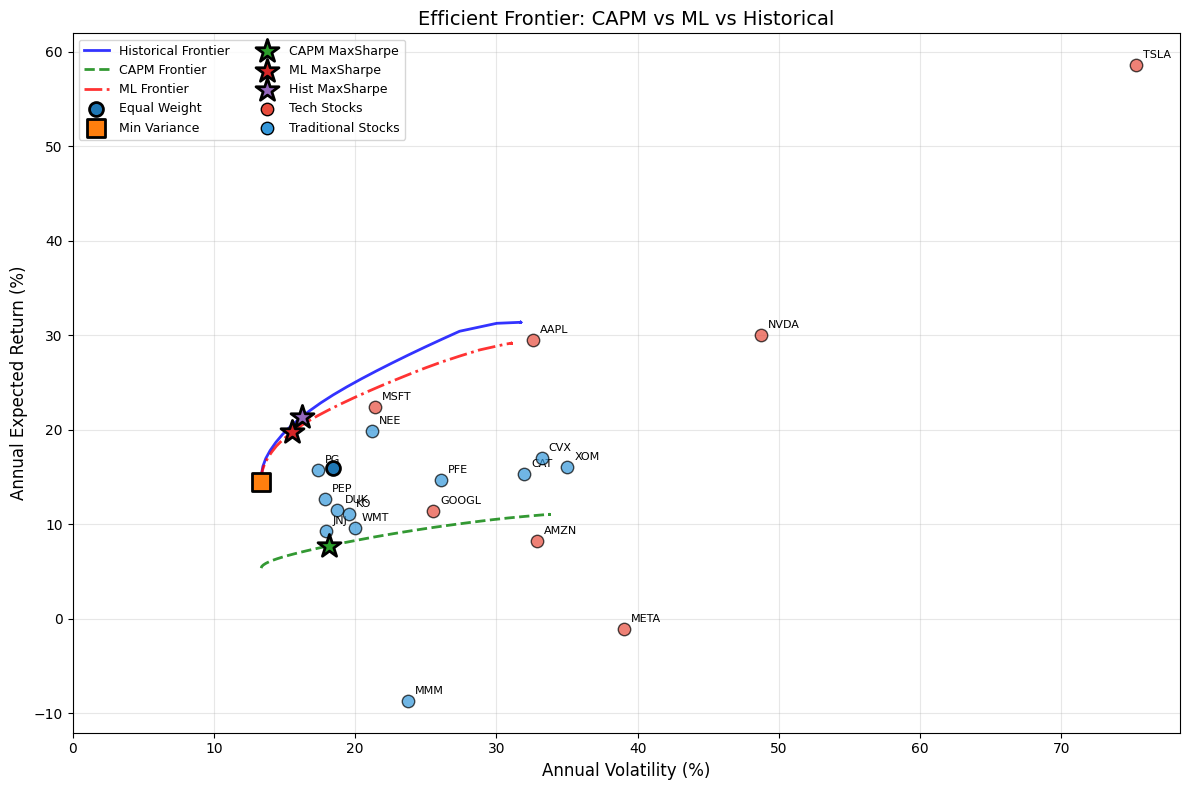

  Saved: opt_01_efficient_frontier.png


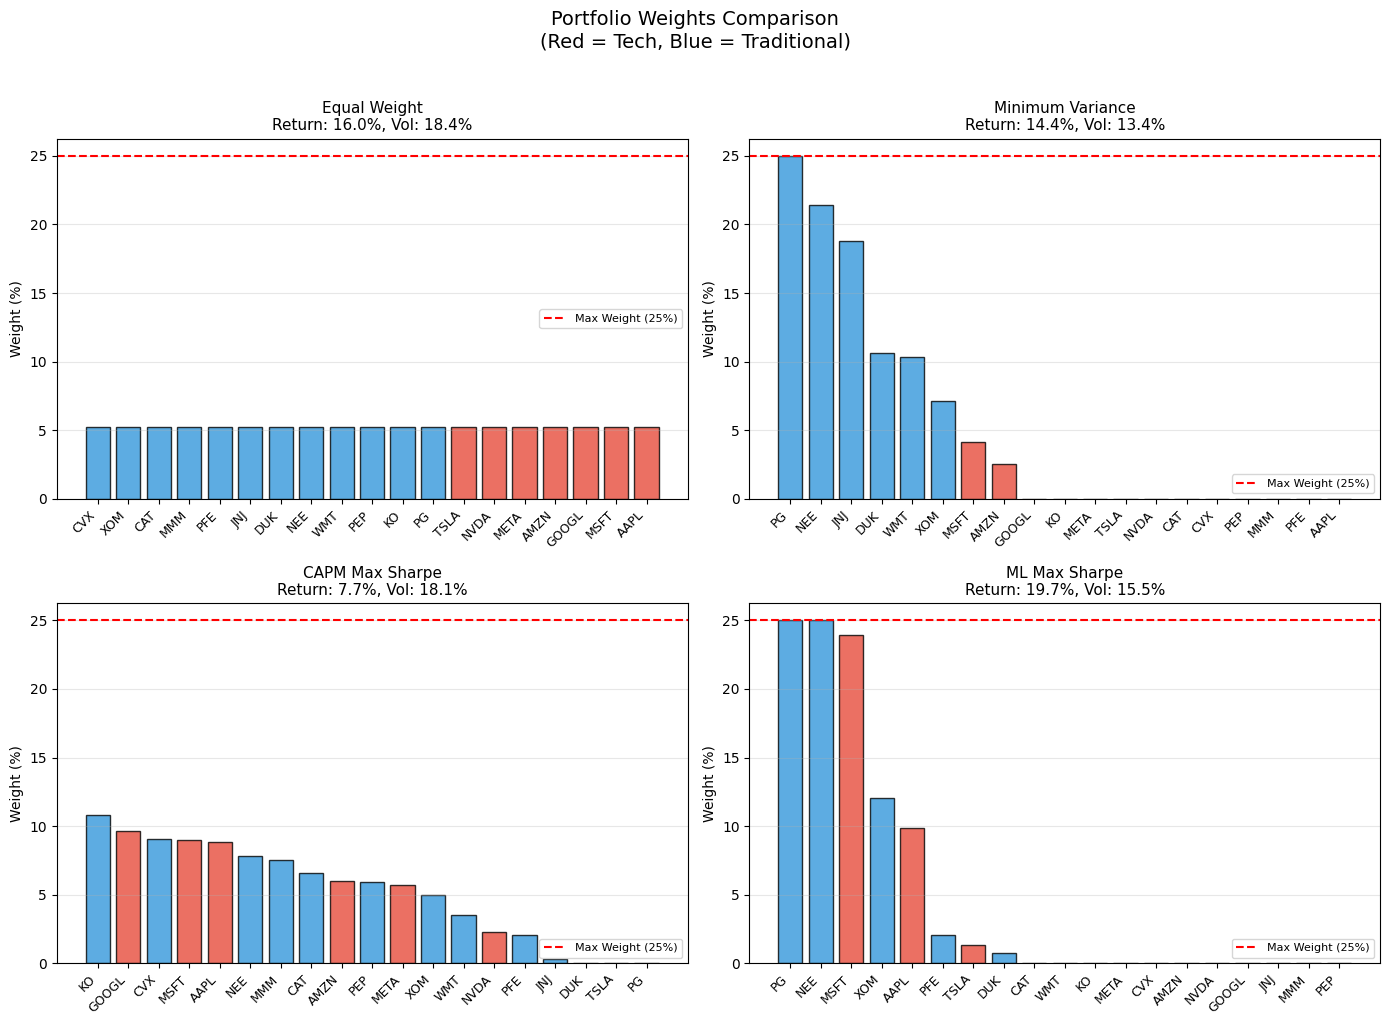

  Saved: opt_02_weights_comparison.png


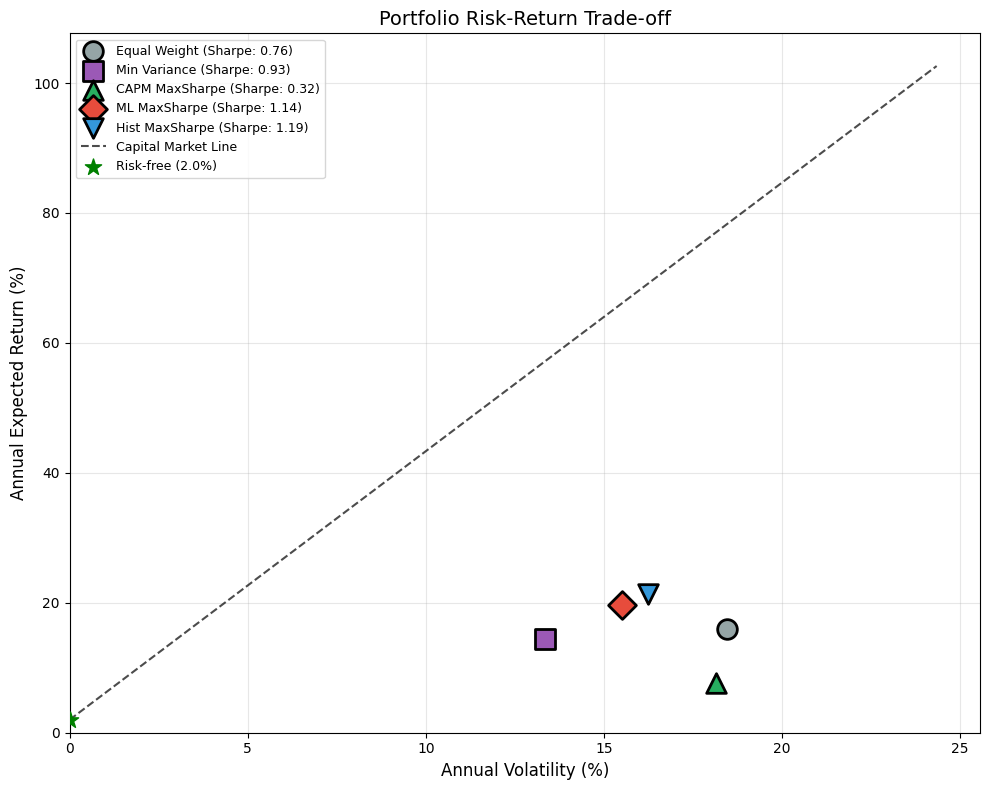

  Saved: opt_03_risk_return.png


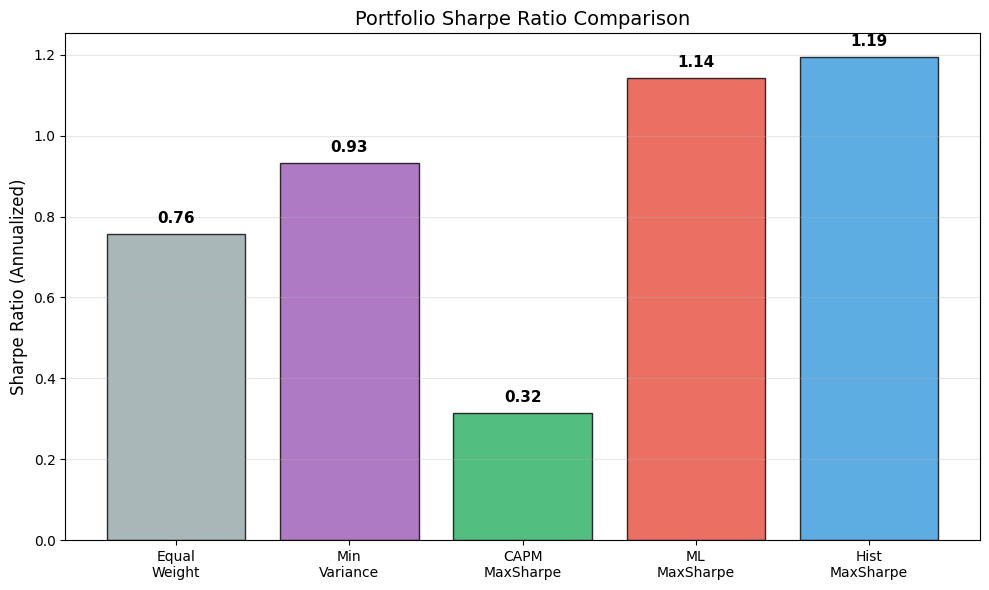

  Saved: opt_04_sharpe_comparison.png


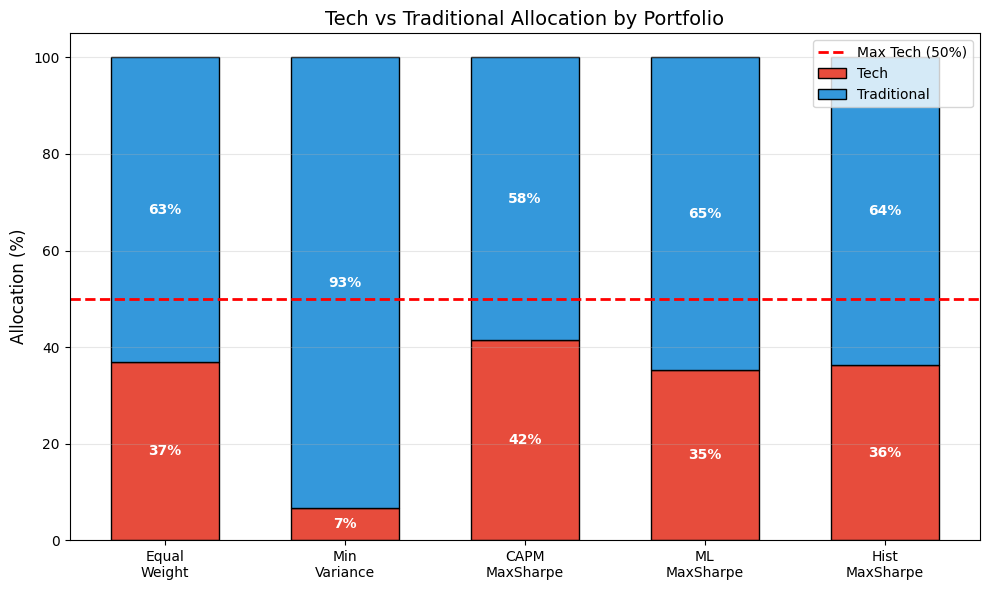

  Saved: opt_05_tech_allocation.png

[9] Saving results...
  Saved: portfolio_weights.csv
  Saved: portfolio_metrics.csv
  Saved: covariance_matrix.csv
  Saved: expected_returns_comparison.csv

[10] Detailed Portfolio Weights...

  CAPM MaxSharpe Portfolio:
  --------------------------------------------------
    KO      10.79%  █████  (Traditional)
    GOOGL    9.62%  ████  (Tech)
    CVX      9.03%  ████  (Traditional)
    MSFT     9.03%  ████  (Tech)
    AAPL     8.85%  ████  (Tech)
    NEE      7.80%  ███  (Traditional)
    MMM      7.56%  ███  (Traditional)
    CAT      6.59%  ███  (Traditional)
    AMZN     6.02%  ███  (Tech)
    PEP      5.90%  ██  (Traditional)
    META     5.70%  ██  (Tech)
    XOM      4.96%  ██  (Traditional)
    WMT      3.52%  █  (Traditional)
    NVDA     2.31%  █  (Tech)
    PFE      2.03%  █  (Traditional)
    JNJ      0.29%    (Traditional)
  --------------------------------------------------

  ML MaxSharpe Portfolio:
  -------------------------------

In [ ]:
"""
Portfolio Optimization using Mean-Variance Framework

Strategies:
    1. CAPM-based optimization
    2. ML-based optimization
    3. Equal-weight benchmark
    4. Minimum variance portfolio

Constraints:
    - No short selling
    - Maximum weight per stock
    - Category constraints (Tech vs Traditional)
"""

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize
import os
import warnings
warnings.filterwarnings('ignore')

print("=" * 70)
print("STEP 4: PORTFOLIO OPTIMIZATION")
print("Mean-Variance Optimization with Constraints")
print("=" * 70)

# ============================================
# CONFIGURATION
# ============================================

SCRIPT_DIR = os.path.dirname('')
PROJECT_DIR = os.path.dirname(SCRIPT_DIR)
DATA_DIR = os.path.join(PROJECT_DIR, 'data')
RESULTS_DIR = os.path.join(PROJECT_DIR, 'results')

os.makedirs(RESULTS_DIR, exist_ok=True)

# Portfolio constraints
MAX_WEIGHT_PER_STOCK = 0.25      # Maximum 25% in any single stock
MAX_TECH_WEIGHT = 0.50           # Maximum 50% in tech stocks
MIN_WEIGHT = 0.00                # No short selling
RISK_FREE_RATE_ANNUAL = 0.02    # 2% annual risk-free rate

# ============================================
# LOAD DATA
# ============================================

print("\n[1] Loading data...")

# Load returns
returns_train = pd.read_csv(
    os.path.join(DATA_DIR, 'returns_train.csv'),
    index_col=0,
    parse_dates=True
)

# Load CAPM results
capm_results = pd.read_csv(
    os.path.join(DATA_DIR, 'capm_results.csv'),
    index_col=0
)

# Load ML predictions
ml_predictions = pd.read_csv(
    os.path.join(DATA_DIR, 'ml_predictions.csv'),
    index_col=0
)

# Load tickers info
tickers_df = pd.read_csv(os.path.join(DATA_DIR, 'tickers.csv'))

tickers = list(returns_train.columns)
n_assets = len(tickers)

print(f"  Number of assets: {n_assets}")
print(f"  Training period: {returns_train.index[0].date()} to {returns_train.index[-1].date()}")

# ============================================
# CALCULATE COVARIANCE MATRIX
# ============================================

print("\n[2] Calculating covariance matrix...")

# Monthly covariance matrix
cov_matrix = returns_train.cov()

# Annualized covariance matrix
cov_matrix_annual = cov_matrix * 12

print(f"  Covariance matrix shape: {cov_matrix.shape}")
print(f"  Average correlation: {returns_train.corr().values[np.triu_indices(n_assets, k=1)].mean():.3f}")

# ============================================
# PREPARE EXPECTED RETURNS
# ============================================

print("\n[3] Preparing expected returns...")

# CAPM expected returns (monthly)
mu_capm = capm_results.loc[tickers, 'expected_return_monthly'].values

# ML expected returns (monthly)
if 'ensemble_pred' in ml_predictions.columns:
    mu_ml = ml_predictions.loc[tickers, 'ensemble_pred'].values
else:
    # Fallback: use historical mean
    mu_ml = returns_train.mean().values

# Historical mean returns (monthly)
mu_hist = returns_train.mean().values

# Annualize
mu_capm_annual = mu_capm * 12
mu_ml_annual = mu_ml * 12
mu_hist_annual = mu_hist * 12

print("\n  Expected Annual Returns:")
print("  " + "-" * 60)
print(f"  {'Ticker':<8} {'CAPM':>10} {'ML':>10} {'Historical':>12} {'Category':>12}")
print("  " + "-" * 60)

# Get category for each ticker
ticker_categories = {}
for ticker in tickers:
    if ticker in capm_results.index and 'category' in capm_results.columns:
        ticker_categories[ticker] = capm_results.loc[ticker, 'category']
    else:
        tech_list = ['AAPL', 'MSFT', 'GOOGL', 'AMZN', 'META', 'NVDA', 'TSLA']
        ticker_categories[ticker] = 'Tech' if ticker in tech_list else 'Traditional'

for i, ticker in enumerate(tickers):
    cat = ticker_categories[ticker]
    print(f"  {ticker:<8} {mu_capm_annual[i]*100:>9.2f}% {mu_ml_annual[i]*100:>9.2f}% "
          f"{mu_hist_annual[i]*100:>11.2f}% {cat:>12}")

print("  " + "-" * 60)

# ============================================
# OPTIMIZATION FUNCTIONS
# ============================================

print("\n[4] Setting up optimization...")

def portfolio_return(weights, mu):
    """Calculate portfolio expected return"""
    return np.dot(weights, mu)

def portfolio_volatility(weights, cov_matrix):
    """Calculate portfolio volatility (std dev)"""
    return np.sqrt(np.dot(weights.T, np.dot(cov_matrix, weights)))

def portfolio_sharpe(weights, mu, cov_matrix, rf=0):
    """Calculate Sharpe ratio"""
    ret = portfolio_return(weights, mu)
    vol = portfolio_volatility(weights, cov_matrix)
    return (ret - rf) / vol if vol > 0 else 0

def neg_sharpe(weights, mu, cov_matrix, rf=0):
    """Negative Sharpe for minimization"""
    return -portfolio_sharpe(weights, mu, cov_matrix, rf)

def optimize_portfolio(mu, cov_matrix, target='max_sharpe',
                       max_weight=0.25, max_tech=0.50,
                       target_return=None, target_vol=None):
    """
    Optimize portfolio weights

    Parameters:
    -----------
    mu : array
        Expected returns (monthly)
    cov_matrix : DataFrame/array
        Covariance matrix (monthly)
    target : str
        'max_sharpe', 'min_variance', or 'target_return'
    max_weight : float
        Maximum weight per asset
    max_tech : float
        Maximum weight in tech stocks
    target_return : float
        Target return for 'target_return' optimization
    target_vol : float
        Target volatility constraint

    Returns:
    --------
    dict with optimal weights and portfolio metrics
    """

    n = len(mu)
    cov = cov_matrix.values if isinstance(cov_matrix, pd.DataFrame) else cov_matrix

    # Initial weights (equal weight)
    w0 = np.ones(n) / n

    # Bounds for each weight
    bounds = tuple((MIN_WEIGHT, max_weight) for _ in range(n))

    # Constraints
    constraints = []

    # Sum of weights = 1
    constraints.append({
        'type': 'eq',
        'fun': lambda w: np.sum(w) - 1.0
    })

    # Tech weight constraint
    tech_indices = [i for i, t in enumerate(tickers) if ticker_categories[t] == 'Tech']
    if len(tech_indices) > 0:
        constraints.append({
            'type': 'ineq',
            'fun': lambda w, idx=tech_indices: max_tech - np.sum(w[idx])
        })

    # Target return constraint
    if target_return is not None:
        constraints.append({
            'type': 'eq',
            'fun': lambda w, tr=target_return: portfolio_return(w, mu) - tr
        })

    # Target volatility constraint
    if target_vol is not None:
        constraints.append({
            'type': 'ineq',
            'fun': lambda w, tv=target_vol: tv - portfolio_volatility(w, cov)
        })

    # Objective function
    if target == 'max_sharpe':
        rf_monthly = RISK_FREE_RATE_ANNUAL / 12
        objective = lambda w: neg_sharpe(w, mu, cov, rf_monthly)
    elif target == 'min_variance':
        objective = lambda w: portfolio_volatility(w, cov)
    elif target == 'target_return':
        objective = lambda w: portfolio_volatility(w, cov)
    else:
        objective = lambda w: neg_sharpe(w, mu, cov, RISK_FREE_RATE_ANNUAL/12)

    # Optimize
    result = minimize(
        objective,
        w0,
        method='SLSQP',
        bounds=bounds,
        constraints=constraints,
        options={'maxiter': 1000, 'ftol': 1e-9}
    )

    if not result.success:
        print(f"    Warning: Optimization may not have converged - {result.message}")

    optimal_weights = result.x

    # Calculate portfolio metrics
    port_return = portfolio_return(optimal_weights, mu)
    port_vol = portfolio_volatility(optimal_weights, cov)
    rf_monthly = RISK_FREE_RATE_ANNUAL / 12
    port_sharpe = (port_return - rf_monthly) / port_vol if port_vol > 0 else 0

    return {
        'weights': optimal_weights,
        'return_monthly': port_return,
        'return_annual': port_return * 12,
        'volatility_monthly': port_vol,
        'volatility_annual': port_vol * np.sqrt(12),
        'sharpe_ratio': port_sharpe * np.sqrt(12),  # Annualized
        'success': result.success
    }

# ============================================
# OPTIMIZE PORTFOLIOS
# ============================================

print("\n[5] Optimizing portfolios...")

# Store all portfolio results
portfolios = {}

# ----- 1. Equal Weight Portfolio -----
print("\n  [5.1] Equal Weight Portfolio...")
eq_weights = np.ones(n_assets) / n_assets
eq_return = portfolio_return(eq_weights, mu_hist)
eq_vol = portfolio_volatility(eq_weights, cov_matrix.values)
rf_monthly = RISK_FREE_RATE_ANNUAL / 12

portfolios['Equal_Weight'] = {
    'weights': eq_weights,
    'return_monthly': eq_return,
    'return_annual': eq_return * 12,
    'volatility_monthly': eq_vol,
    'volatility_annual': eq_vol * np.sqrt(12),
    'sharpe_ratio': (eq_return - rf_monthly) / eq_vol * np.sqrt(12),
    'method': 'Equal Weight'
}
print(f"        Return: {eq_return*12*100:.2f}% | Vol: {eq_vol*np.sqrt(12)*100:.2f}%")

# ----- 2. Minimum Variance Portfolio -----
print("\n  [5.2] Minimum Variance Portfolio...")
min_var = optimize_portfolio(mu_hist, cov_matrix, target='min_variance')
min_var['method'] = 'Minimum Variance'
portfolios['Min_Variance'] = min_var
print(f"        Return: {min_var['return_annual']*100:.2f}% | Vol: {min_var['volatility_annual']*100:.2f}%")

# ----- 3. CAPM Max Sharpe Portfolio -----
print("\n  [5.3] CAPM Max Sharpe Portfolio...")
capm_sharpe = optimize_portfolio(mu_capm, cov_matrix, target='max_sharpe')
capm_sharpe['method'] = 'CAPM Max Sharpe'
portfolios['CAPM_MaxSharpe'] = capm_sharpe
print(f"        Return: {capm_sharpe['return_annual']*100:.2f}% | Vol: {capm_sharpe['volatility_annual']*100:.2f}%")
print(f"        Sharpe: {capm_sharpe['sharpe_ratio']:.3f}")

# ----- 4. ML Max Sharpe Portfolio -----
print("\n  [5.4] ML Max Sharpe Portfolio...")
ml_sharpe = optimize_portfolio(mu_ml, cov_matrix, target='max_sharpe')
ml_sharpe['method'] = 'ML Max Sharpe'
portfolios['ML_MaxSharpe'] = ml_sharpe
print(f"        Return: {ml_sharpe['return_annual']*100:.2f}% | Vol: {ml_sharpe['volatility_annual']*100:.2f}%")
print(f"        Sharpe: {ml_sharpe['sharpe_ratio']:.3f}")

# ----- 5. Historical Max Sharpe Portfolio -----
print("\n  [5.5] Historical Max Sharpe Portfolio...")
hist_sharpe = optimize_portfolio(mu_hist, cov_matrix, target='max_sharpe')
hist_sharpe['method'] = 'Historical Max Sharpe'
portfolios['Hist_MaxSharpe'] = hist_sharpe
print(f"        Return: {hist_sharpe['return_annual']*100:.2f}% | Vol: {hist_sharpe['volatility_annual']*100:.2f}%")
print(f"        Sharpe: {hist_sharpe['sharpe_ratio']:.3f}")

# ============================================
# PORTFOLIO COMPARISON
# ============================================

print("\n[6] Portfolio Comparison...")
print("\n" + "=" * 85)
print(f"{'Portfolio':<22} {'Ann. Return':>12} {'Ann. Vol':>12} {'Sharpe':>10} {'Tech %':>10} {'# Stocks':>10}")
print("=" * 85)

for name, port in portfolios.items():
    weights = port['weights']
    tech_weight = sum(weights[i] for i, t in enumerate(tickers) if ticker_categories[t] == 'Tech')
    n_stocks = np.sum(weights > 0.01)  # Stocks with >1% weight

    print(f"{name:<22} {port['return_annual']*100:>11.2f}% {port['volatility_annual']*100:>11.2f}% "
          f"{port['sharpe_ratio']:>10.3f} {tech_weight*100:>9.1f}% {n_stocks:>10.0f}")

print("=" * 85)

# ============================================
# EFFICIENT FRONTIER
# ============================================

print("\n[7] Calculating Efficient Frontier...")

def calculate_efficient_frontier(mu, cov_matrix, n_points=50):
    """Calculate points on the efficient frontier"""

    # Find min and max return portfolios
    min_var_port = optimize_portfolio(mu, cov_matrix, target='min_variance')

    # Use individual asset returns as bounds
    min_ret = min_var_port['return_monthly']
    max_ret = max(mu) * 0.95  # 95% of max individual return

    target_returns = np.linspace(min_ret, max_ret, n_points)

    frontier_vol = []
    frontier_ret = []
    frontier_weights = []

    for target_ret in target_returns:
        try:
            port = optimize_portfolio(mu, cov_matrix, target='target_return',
                                      target_return=target_ret)
            if port['success'] or port['volatility_monthly'] > 0:
                frontier_ret.append(port['return_monthly'])
                frontier_vol.append(port['volatility_monthly'])
                frontier_weights.append(port['weights'])
        except:
            continue

    return np.array(frontier_ret), np.array(frontier_vol), frontier_weights

# Calculate frontiers for different expected returns
print("  Calculating CAPM frontier...")
capm_ret, capm_vol, capm_weights = calculate_efficient_frontier(mu_capm, cov_matrix)

print("  Calculating ML frontier...")
ml_ret, ml_vol, ml_weights = calculate_efficient_frontier(mu_ml, cov_matrix)

print("  Calculating Historical frontier...")
hist_ret, hist_vol, hist_weights = calculate_efficient_frontier(mu_hist, cov_matrix)

# ============================================
# VISUALIZATIONS
# ============================================

print("\n[8] Creating visualizations...")

# ----- Figure 1: Efficient Frontier Comparison -----
fig1, ax1 = plt.subplots(figsize=(12, 8))

# Plot individual assets
for i, ticker in enumerate(tickers):
    color = '#e74c3c' if ticker_categories[ticker] == 'Tech' else '#3498db'
    ax1.scatter(returns_train[ticker].std() * np.sqrt(12) * 100,
                mu_hist_annual[i] * 100,
                color=color, s=80, alpha=0.7, edgecolor='black', zorder=5)
    ax1.annotate(ticker,
                 (returns_train[ticker].std() * np.sqrt(12) * 100, mu_hist_annual[i] * 100),
                 textcoords="offset points", xytext=(5, 5), fontsize=8)

# Plot frontiers
ax1.plot(hist_vol * np.sqrt(12) * 100, hist_ret * 12 * 100,
         'b-', linewidth=2, label='Historical Frontier', alpha=0.8)
ax1.plot(capm_vol * np.sqrt(12) * 100, capm_ret * 12 * 100,
         'g--', linewidth=2, label='CAPM Frontier', alpha=0.8)
ax1.plot(ml_vol * np.sqrt(12) * 100, ml_ret * 12 * 100,
         'r-.', linewidth=2, label='ML Frontier', alpha=0.8)

# Plot optimal portfolios
for name, port in portfolios.items():
    if 'MaxSharpe' in name:
        marker = '*'
        size = 300
    elif name == 'Min_Variance':
        marker = 's'
        size = 150
    else:
        marker = 'o'
        size = 100

    ax1.scatter(port['volatility_annual'] * 100, port['return_annual'] * 100,
                marker=marker, s=size, zorder=10, edgecolor='black', linewidth=2,
                label=f"{name.replace('_', ' ')}")

# Legend for categories
ax1.scatter([], [], color='#e74c3c', s=80, label='Tech Stocks', edgecolor='black')
ax1.scatter([], [], color='#3498db', s=80, label='Traditional Stocks', edgecolor='black')

ax1.set_xlabel('Annual Volatility (%)', fontsize=12)
ax1.set_ylabel('Annual Expected Return (%)', fontsize=12)
ax1.set_title('Efficient Frontier: CAPM vs ML vs Historical', fontsize=14)
ax1.legend(loc='upper left', fontsize=9, ncol=2)
ax1.grid(True, alpha=0.3)
ax1.set_xlim(left=0)

plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, 'opt_01_efficient_frontier.png'), dpi=150, bbox_inches='tight')
plt.show()
print(f"  Saved: opt_01_efficient_frontier.png")


# ----- Figure 2: Portfolio Weights Comparison -----
fig2, axes2 = plt.subplots(2, 2, figsize=(14, 10))

portfolios_to_plot = ['Equal_Weight', 'Min_Variance', 'CAPM_MaxSharpe', 'ML_MaxSharpe']
titles = ['Equal Weight', 'Minimum Variance', 'CAPM Max Sharpe', 'ML Max Sharpe']

for idx, (port_name, title) in enumerate(zip(portfolios_to_plot, titles)):
    ax = axes2[idx // 2, idx % 2]
    weights = portfolios[port_name]['weights']

    # Sort by weight
    sorted_idx = np.argsort(weights)[::-1]
    sorted_weights = weights[sorted_idx]
    sorted_tickers = [tickers[i] for i in sorted_idx]
    sorted_colors = ['#e74c3c' if ticker_categories[t] == 'Tech' else '#3498db'
                     for t in sorted_tickers]

    bars = ax.bar(range(n_assets), sorted_weights * 100, color=sorted_colors,
                  edgecolor='black', alpha=0.8)
    ax.set_xticks(range(n_assets))
    ax.set_xticklabels(sorted_tickers, rotation=45, ha='right', fontsize=9)
    ax.set_ylabel('Weight (%)', fontsize=10)
    ax.set_title(f'{title}\nReturn: {portfolios[port_name]["return_annual"]*100:.1f}%, '
                 f'Vol: {portfolios[port_name]["volatility_annual"]*100:.1f}%', fontsize=11)
    ax.axhline(y=MAX_WEIGHT_PER_STOCK * 100, color='red', linestyle='--',
               linewidth=1.5, label=f'Max Weight ({MAX_WEIGHT_PER_STOCK*100:.0f}%)')
    ax.legend(fontsize=8)
    ax.grid(axis='y', alpha=0.3)

plt.suptitle('Portfolio Weights Comparison\n(Red = Tech, Blue = Traditional)', fontsize=14, y=1.02)
plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, 'opt_02_weights_comparison.png'), dpi=150, bbox_inches='tight')
plt.show()
print(f"  Saved: opt_02_weights_comparison.png")


# ----- Figure 3: Risk-Return Trade-off -----
fig3, ax3 = plt.subplots(figsize=(10, 8))

colors = {'Equal_Weight': '#95a5a6', 'Min_Variance': '#9b59b6',
          'CAPM_MaxSharpe': '#27ae60', 'ML_MaxSharpe': '#e74c3c',
          'Hist_MaxSharpe': '#3498db'}
markers = {'Equal_Weight': 'o', 'Min_Variance': 's',
           'CAPM_MaxSharpe': '^', 'ML_MaxSharpe': 'D',
           'Hist_MaxSharpe': 'v'}

for name, port in portfolios.items():
    ax3.scatter(port['volatility_annual'] * 100, port['return_annual'] * 100,
                color=colors.get(name, '#333333'),
                marker=markers.get(name, 'o'),
                s=200, edgecolor='black', linewidth=2, zorder=5,
                label=f"{name.replace('_', ' ')} (Sharpe: {port['sharpe_ratio']:.2f})")

# Capital Market Line (using highest Sharpe portfolio)
best_sharpe_port = max(portfolios.values(), key=lambda x: x['sharpe_ratio'])
rf_annual = RISK_FREE_RATE_ANNUAL
cml_vol = np.linspace(0, best_sharpe_port['volatility_annual'] * 1.5, 100)
cml_ret = rf_annual + (best_sharpe_port['sharpe_ratio'] / np.sqrt(12) * 12) * cml_vol
ax3.plot(cml_vol * 100, cml_ret * 100, 'k--', linewidth=1.5,
         label='Capital Market Line', alpha=0.7)

ax3.scatter(0, rf_annual * 100, color='green', s=150, marker='*',
            zorder=6, label=f'Risk-free ({rf_annual*100:.1f}%)')

ax3.set_xlabel('Annual Volatility (%)', fontsize=12)
ax3.set_ylabel('Annual Expected Return (%)', fontsize=12)
ax3.set_title('Portfolio Risk-Return Trade-off', fontsize=14)
ax3.legend(loc='upper left', fontsize=9)
ax3.grid(True, alpha=0.3)
ax3.set_xlim(left=0)
ax3.set_ylim(bottom=0)

plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, 'opt_03_risk_return.png'), dpi=150, bbox_inches='tight')
plt.show()
print(f"  Saved: opt_03_risk_return.png")


# ----- Figure 4: Sharpe Ratio Comparison -----
fig4, ax4 = plt.subplots(figsize=(10, 6))

port_names = list(portfolios.keys())
sharpe_ratios = [portfolios[p]['sharpe_ratio'] for p in port_names]
port_colors = [colors.get(p, '#333333') for p in port_names]

bars = ax4.bar(range(len(port_names)), sharpe_ratios, color=port_colors,
               edgecolor='black', alpha=0.8)

ax4.set_xticks(range(len(port_names)))
ax4.set_xticklabels([p.replace('_', '\n') for p in port_names], fontsize=10)
ax4.set_ylabel('Sharpe Ratio (Annualized)', fontsize=12)
ax4.set_title('Portfolio Sharpe Ratio Comparison', fontsize=14)
ax4.axhline(y=0, color='black', linestyle='-', linewidth=0.5)
ax4.grid(axis='y', alpha=0.3)

# Add value labels
for bar, val in zip(bars, sharpe_ratios):
    ax4.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.02,
             f'{val:.2f}', ha='center', va='bottom', fontsize=11, fontweight='bold')

plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, 'opt_04_sharpe_comparison.png'), dpi=150, bbox_inches='tight')
plt.show()
print(f"  Saved: opt_04_sharpe_comparison.png")


# ----- Figure 5: Tech vs Traditional Allocation -----
fig5, ax5 = plt.subplots(figsize=(10, 6))

tech_weights = []
trad_weights = []

for name in portfolios:
    weights = portfolios[name]['weights']
    tech_w = sum(weights[i] for i, t in enumerate(tickers) if ticker_categories[t] == 'Tech')
    trad_w = sum(weights[i] for i, t in enumerate(tickers) if ticker_categories[t] == 'Traditional')
    tech_weights.append(tech_w * 100)
    trad_weights.append(trad_w * 100)

x_pos = np.arange(len(portfolios))
width = 0.6

ax5.bar(x_pos, tech_weights, width, label='Tech', color='#e74c3c', edgecolor='black')
ax5.bar(x_pos, trad_weights, width, bottom=tech_weights, label='Traditional',
        color='#3498db', edgecolor='black')

ax5.axhline(y=MAX_TECH_WEIGHT * 100, color='red', linestyle='--', linewidth=2,
            label=f'Max Tech ({MAX_TECH_WEIGHT*100:.0f}%)')

ax5.set_xticks(x_pos)
ax5.set_xticklabels([p.replace('_', '\n') for p in portfolios.keys()], fontsize=10)
ax5.set_ylabel('Allocation (%)', fontsize=12)
ax5.set_title('Tech vs Traditional Allocation by Portfolio', fontsize=14)
ax5.legend(loc='upper right', fontsize=10)
ax5.set_ylim(0, 105)
ax5.grid(axis='y', alpha=0.3)

# Add percentage labels
for i, (tech_w, trad_w) in enumerate(zip(tech_weights, trad_weights)):
    ax5.text(i, tech_w/2, f'{tech_w:.0f}%', ha='center', va='center',
             fontsize=10, fontweight='bold', color='white')
    ax5.text(i, tech_w + trad_w/2, f'{trad_w:.0f}%', ha='center', va='center',
             fontsize=10, fontweight='bold', color='white')

plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, 'opt_05_tech_allocation.png'), dpi=150, bbox_inches='tight')
plt.show()
print(f"  Saved: opt_05_tech_allocation.png")

# ============================================
# SAVE RESULTS
# ============================================

print("\n[9] Saving results...")

# Save portfolio weights
weights_df = pd.DataFrame({
    name: port['weights'] for name, port in portfolios.items()
}, index=tickers)
weights_df.to_csv(os.path.join(DATA_DIR, 'portfolio_weights.csv'))
print(f"  Saved: portfolio_weights.csv")

# Save portfolio metrics
metrics_list = []
for name, port in portfolios.items():
    weights = port['weights']
    tech_weight = sum(weights[i] for i, t in enumerate(tickers) if ticker_categories[t] == 'Tech')
    n_stocks = np.sum(weights > 0.01)

    metrics_list.append({
        'portfolio': name,
        'return_annual': port['return_annual'],
        'volatility_annual': port['volatility_annual'],
        'sharpe_ratio': port['sharpe_ratio'],
        'tech_weight': tech_weight,
        'n_stocks': n_stocks
    })

metrics_df = pd.DataFrame(metrics_list)
metrics_df.to_csv(os.path.join(DATA_DIR, 'portfolio_metrics.csv'), index=False)
print(f"  Saved: portfolio_metrics.csv")

# Save covariance matrix
cov_matrix.to_csv(os.path.join(DATA_DIR, 'covariance_matrix.csv'))
print(f"  Saved: covariance_matrix.csv")

# Save expected returns comparison
expected_returns_df = pd.DataFrame({
    'ticker': tickers,
    'mu_capm_monthly': mu_capm,
    'mu_ml_monthly': mu_ml,
    'mu_hist_monthly': mu_hist,
    'mu_capm_annual': mu_capm_annual,
    'mu_ml_annual': mu_ml_annual,
    'mu_hist_annual': mu_hist_annual,
    'category': [ticker_categories[t] for t in tickers]
})
expected_returns_df.to_csv(os.path.join(DATA_DIR, 'expected_returns_comparison.csv'), index=False)
print(f"  Saved: expected_returns_comparison.csv")

# ============================================
# DETAILED WEIGHTS OUTPUT
# ============================================

print("\n[10] Detailed Portfolio Weights...")

for port_name in ['CAPM_MaxSharpe', 'ML_MaxSharpe']:
    print(f"\n  {port_name.replace('_', ' ')} Portfolio:")
    print("  " + "-" * 50)
    weights = portfolios[port_name]['weights']

    # Sort by weight descending
    sorted_pairs = sorted(zip(tickers, weights), key=lambda x: x[1], reverse=True)

    for ticker, weight in sorted_pairs:
        if weight > 0.001:  # Only show if > 0.1%
            cat = ticker_categories[ticker]
            bar = "█" * int(weight * 50)
            print(f"    {ticker:<6} {weight*100:>6.2f}%  {bar}  ({cat})")
    print("  " + "-" * 50)

# ============================================
# SUMMARY
# ============================================

print("\n" + "=" * 70)
print("PORTFOLIO OPTIMIZATION SUMMARY")
print("=" * 70)

# Find best portfolio
best_port_name = max(portfolios.keys(), key=lambda x: portfolios[x]['sharpe_ratio'])
best_port = portfolios[best_port_name]

# Calculate some stats
capm_sharpe = portfolios['CAPM_MaxSharpe']['sharpe_ratio']
ml_sharpe = portfolios['ML_MaxSharpe']['sharpe_ratio']

print(f"""
Optimization Settings:
----------------------
- Maximum weight per stock: {MAX_WEIGHT_PER_STOCK*100:.0f}%
- Maximum tech allocation: {MAX_TECH_WEIGHT*100:.0f}%
- Risk-free rate: {RISK_FREE_RATE_ANNUAL*100:.1f}%

Portfolio Comparison:
---------------------
{'Portfolio':<20} {'Return':>10} {'Volatility':>12} {'Sharpe':>10}
{'-'*55}""")

for name, port in portfolios.items():
    print(f"{name:<20} {port['return_annual']*100:>9.2f}% {port['volatility_annual']*100:>11.2f}% {port['sharpe_ratio']:>10.3f}")

print(f"""
Best Portfolio (by Sharpe Ratio):
---------------------------------
{best_port_name.replace('_', ' ')}
  - Expected Annual Return: {best_port['return_annual']*100:.2f}%
  - Annual Volatility: {best_port['volatility_annual']*100:.2f}%
  - Sharpe Ratio: {best_port['sharpe_ratio']:.3f}

CAPM vs ML Comparison:
----------------------
- CAPM Sharpe Ratio: {capm_sharpe:.3f}
- ML Sharpe Ratio: {ml_sharpe:.3f}
- Difference: {(ml_sharpe - capm_sharpe):.3f} {'(ML better)' if ml_sharpe > capm_sharpe else '(CAPM better)'}

Files Saved:
------------
Data files:
  - portfolio_weights.csv
  - portfolio_metrics.csv
  - covariance_matrix.csv
  - expected_returns_comparison.csv

Figures (5 images):
  - opt_01_efficient_frontier.png
  - opt_02_weights_comparison.png
  - opt_03_risk_return.png
  - opt_04_sharpe_comparison.png
  - opt_05_tech_allocation.png

""")

print("=" * 70)
print("PORTFOLIO OPTIMIZATION COMPLETE!")
print("=" * 70)

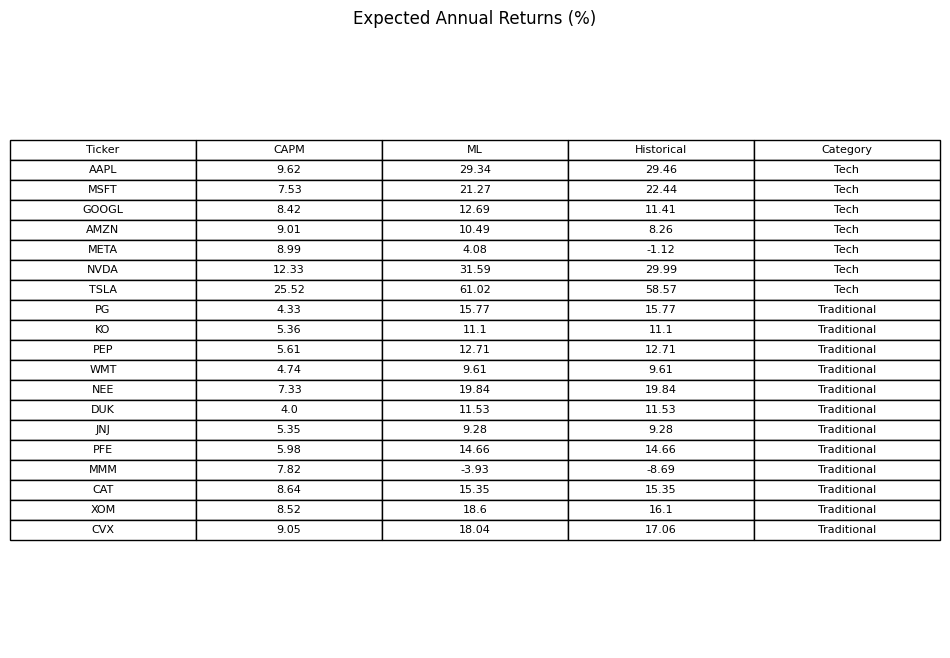

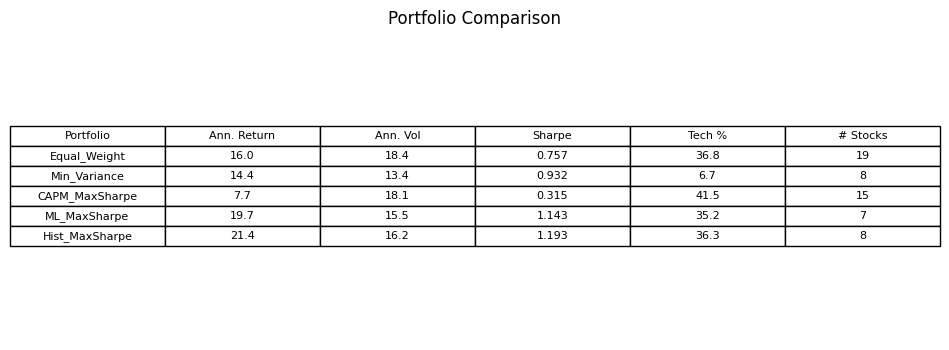

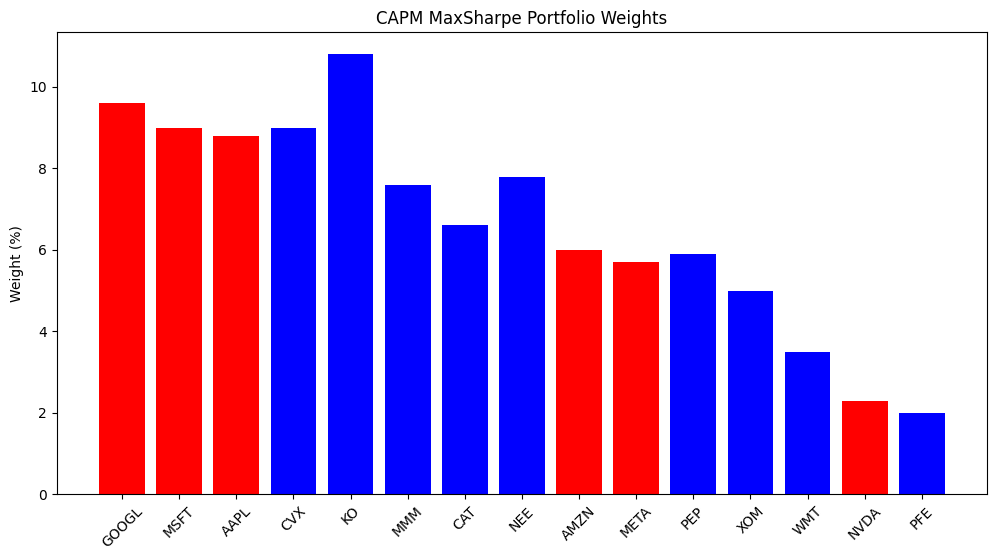

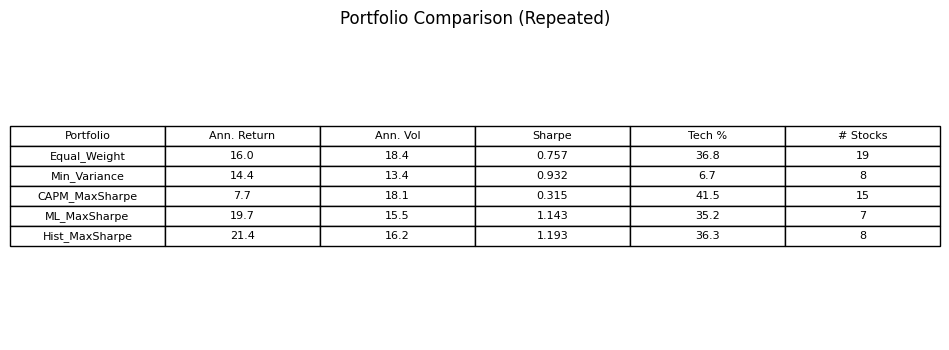

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from io import BytesIO

# Data for Expected Annual Returns (from script example, annualized %)
data_ear = {
    'Ticker': ['AAPL', 'MSFT', 'GOOGL', 'AMZN', 'META', 'NVDA', 'TSLA', 'PG', 'KO', 'PEP', 'WMT', 'NEE', 'DUK', 'JNJ', 'PFE', 'MMM', 'CAT', 'XOM', 'CVX'],
    'CAPM': [9.62, 7.53, 8.42, 9.01, 8.99, 12.33, 25.52, 4.33, 5.36, 5.61, 4.74, 7.33, 4.00, 5.35, 5.98, 7.82, 8.64, 8.52, 9.05],
    'ML': [29.34, 21.27, 12.69, 10.49, 4.08, 31.59, 61.02, 15.77, 11.10, 12.71, 9.61, 19.84, 11.53, 9.28, 14.66, -3.93, 15.35, 18.60, 18.04],
    'Historical': [29.46, 22.44, 11.41, 8.26, -1.12, 29.99, 58.57, 15.77, 11.10, 12.71, 9.61, 19.84, 11.53, 9.28, 14.66, -8.69, 15.35, 16.10, 17.06],
    'Category': ['Tech', 'Tech', 'Tech', 'Tech', 'Tech', 'Tech', 'Tech', 'Traditional', 'Traditional', 'Traditional', 'Traditional', 'Traditional', 'Traditional', 'Traditional', 'Traditional', 'Traditional', 'Traditional', 'Traditional', 'Traditional']
}
df_ear = pd.DataFrame(data_ear)

# Plot as table
fig1, ax1 = plt.subplots(figsize=(10, 8))
ax1.axis('tight')
ax1.axis('off')
table1 = ax1.table(cellText=df_ear.values, colLabels=df_ear.columns, cellLoc='center', loc='center')
table1.auto_set_font_size(False)
table1.set_fontsize(8)
table1.scale(1.2, 1.2)
plt.title('Expected Annual Returns (%)')
plt.show()

# Data for Portfolio Comparison
data_pc = {
    'Portfolio': ['Equal_Weight', 'Min_Variance', 'CAPM_MaxSharpe', 'ML_MaxSharpe', 'Hist_MaxSharpe'],
    'Ann. Return': [16.0, 14.4, 7.7, 19.7, 21.4],
    'Ann. Vol': [18.4, 13.4, 18.1, 15.5, 16.2],
    'Sharpe': [0.757, 0.932, 0.315, 1.143, 1.193],
    'Tech %': [36.8, 6.7, 41.5, 35.2, 36.3],
    '# Stocks': [19, 8, 15, 7, 8]
}
df_pc = pd.DataFrame(data_pc)

# Plot as table
fig2, ax2 = plt.subplots(figsize=(10, 4))
ax2.axis('tight')
ax2.axis('off')
table2 = ax2.table(cellText=df_pc.values, colLabels=df_pc.columns, cellLoc='center', loc='center')
table2.auto_set_font_size(False)
table2.set_fontsize(8)
table2.scale(1.2, 1.2)
plt.title('Portfolio Comparison')
plt.show()

# Data for CAPM MaxSharpe Portfolio weights (from script, %)
data_cms = {
    'Ticker': ['GOOGL', 'MSFT', 'AAPL', 'CVX', 'KO', 'MMM', 'CAT', 'NEE', 'AMZN', 'META', 'PEP', 'XOM', 'WMT', 'NVDA', 'PFE'],
    'Weight': [9.6, 9.0, 8.8, 9.0, 10.8, 7.6, 6.6, 7.8, 6.0, 5.7, 5.9, 5.0, 3.5, 2.3, 2.0],
    'Category': ['Tech', 'Tech', 'Tech', 'Traditional', 'Traditional', 'Traditional', 'Traditional', 'Traditional', 'Tech', 'Tech', 'Traditional', 'Traditional', 'Traditional', 'Tech', 'Traditional']
}
df_cms = pd.DataFrame(data_cms)

# Plot as bar chart
fig3, ax3 = plt.subplots(figsize=(12, 6))
ax3.bar(df_cms['Ticker'], df_cms['Weight'], color=['red' if cat=='Tech' else 'blue' for cat in df_cms['Category']])
ax3.set_ylabel('Weight (%)')
ax3.set_title('CAPM MaxSharpe Portfolio Weights')
plt.xticks(rotation=45)
plt.show()

# Portfolio Comparison again as table (same as above)
fig4, ax4 = plt.subplots(figsize=(10, 4))
ax4.axis('tight')
ax4.axis('off')
table4 = ax4.table(cellText=df_pc.values, colLabels=df_pc.columns, cellLoc='center', loc='center')
table4.auto_set_font_size(False)
table4.set_fontsize(8)
table4.scale(1.2, 1.2)
plt.title('Portfolio Comparison (Repeated)')
plt.show()

STEP 3: MACHINE LEARNING MODEL
Predicting Stock Returns with ML

[1] Loading data...
  Stocks: 19
  Training months: 59
  Date range: 2018-02-01 to 2022-12-01

[2] Creating features...
  Creating momentum, volatility, and market features...
  Total samples: 893
  Samples per stock: ~47
  Number of features: 19

  Features created:
     1. return_current
     2. momentum_1m
     3. momentum_3m
     4. momentum_6m
     5. momentum_12m
     6. volatility_3m
     7. volatility_6m
     8. volatility_12m
     9. mean_reversion_6m
    10. mean_reversion_12m
    11. market_return
    12. market_volatility_3m
    13. market_momentum_3m
    14. excess_vs_market
    15. rolling_corr_12m
    16. rf_rate
    17. return_lag1
    18. return_lag2
    19. return_lag3

[3] Preparing data for modeling...
  X shape: (893, 19)
  y shape: (893,)
  Features standardized: mean=0, std=1

[4] Feature Selection with Ridge Regression...
  Selected 15 features ( |coef| > 0.001 ):
    - return_lag3
    - volatility

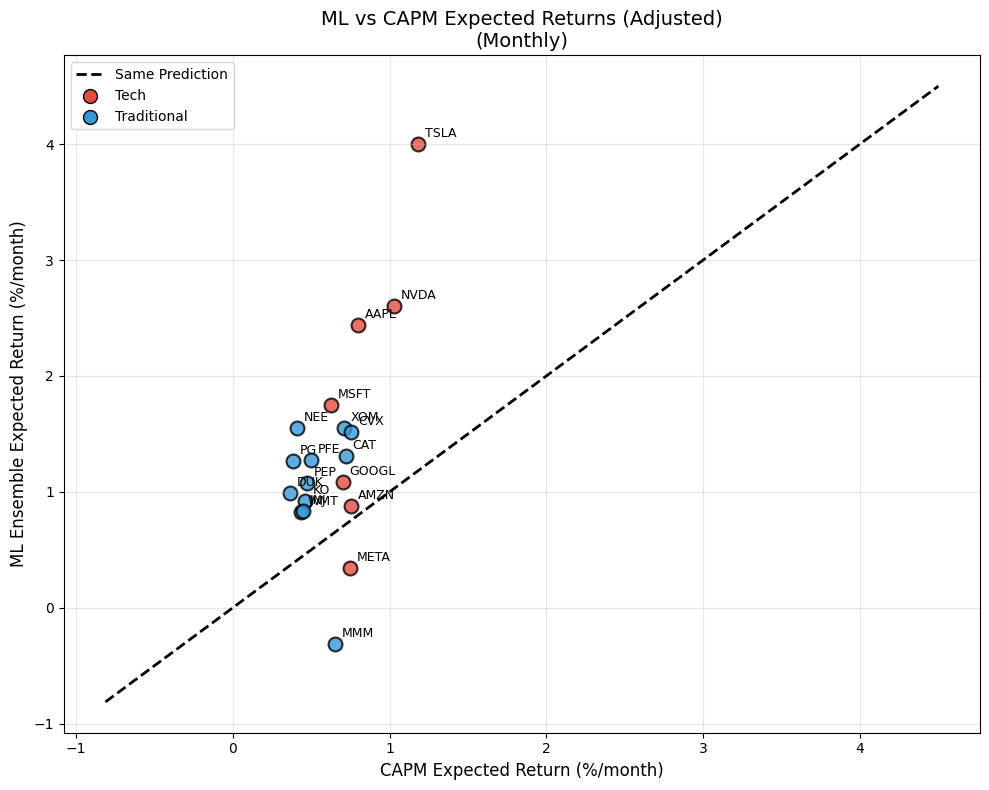

In [ ]:
"""
Machine Learning Models for Stock Return Prediction

Models:
    1. Ridge Regression (Linear) - for feature selection
    2. Lasso Regression (Linear)
    3. Random Forest (Non-linear)
    4. XGBoost (Gradient Boosting)

Features:
    - Momentum (past returns)
    - Volatility (rolling std)
    - Mean reversion signals
    - Market factors
"""

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import Ridge, Lasso
from sklearn.ensemble import RandomForestRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import TimeSeriesSplit, cross_val_score
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error
import os
import warnings
warnings.filterwarnings('ignore')

# Try to import xgboost
HAS_XGBOOST = False
try:
    import xgboost as xgb
    HAS_XGBOOST = True
except ImportError:
    from sklearn.ensemble import GradientBoostingRegressor
    print("Note: XGBoost not installed, using GradientBoostingRegressor instead")

print("=" * 70)
print("STEP 3: MACHINE LEARNING MODEL")
print("Predicting Stock Returns with ML")
print("=" * 70)

# ============================================
# CONFIGURATION
# ============================================

# Feature parameters
MOMENTUM_WINDOWS = [1, 3, 6, 12]  # months
VOLATILITY_WINDOWS = [3, 6, 12]   # months

# ============================================
# LOAD DATA
# ============================================

print("\n[1] Loading data...")

returns_train = pd.read_csv('returns_train.csv',
    index_col=0,
    parse_dates=True
)

market_returns_train = pd.read_csv('market_returns_train.csv',
    index_col=0,
    parse_dates=True
)

rf_train = pd.read_csv('rf_train.csv',
    index_col=0,
    parse_dates=True
)

capm_results = pd.read_csv('capm_results.csv',
    index_col=0
)

tickers_df = pd.read_csv('tickers.csv')

# Convert to Series
if isinstance(market_returns_train, pd.DataFrame):
    market_returns_train = market_returns_train.iloc[:, 0]

if isinstance(rf_train, pd.DataFrame):
    rf_train = rf_train.iloc[:, 0]

tickers = list(returns_train.columns)

print(f"  Stocks: {len(tickers)}")
print(f"  Training months: {len(returns_train)}")
print(f"  Date range: {returns_train.index[0].date()} to {returns_train.index[-1].date()}")

# ============================================
# FEATURE ENGINEERING
# ============================================

print("\n[2] Creating features...")

def create_features(returns_df, market_returns, rf_rate):
    """
    Create features for ML model

    Features:
    - Momentum: past cumulative returns
    - Volatility: rolling standard deviation
    - Mean reversion: return vs moving average
    - Market factors: market return, volatility
    - Rolling correlation with market
    """

    features_list = []

    for ticker in returns_df.columns:
        stock_returns = returns_df[ticker]

        feat = pd.DataFrame(index=returns_df.index)
        feat['ticker'] = ticker

        # Target: next month return
        feat['target'] = stock_returns.shift(-1)

        # Current return
        feat['return_current'] = stock_returns

        # ----- Momentum Features -----
        for window in MOMENTUM_WINDOWS:
            feat[f'momentum_{window}m'] = stock_returns.rolling(window).sum()

        # ----- Volatility Features -----
        for window in VOLATILITY_WINDOWS:
            feat[f'volatility_{window}m'] = stock_returns.rolling(window).std()

        # ----- Mean Reversion Features -----
        feat['mean_reversion_6m'] = stock_returns - stock_returns.rolling(6).mean()
        feat['mean_reversion_12m'] = stock_returns - stock_returns.rolling(12).mean()

        # ----- Market Factors -----
        feat['market_return'] = market_returns
        feat['market_volatility_3m'] = market_returns.rolling(3).std()
        feat['market_momentum_3m'] = market_returns.rolling(3).sum()

        # Excess return over market
        feat['excess_vs_market'] = stock_returns - market_returns

        # ----- Rolling Beta -----
        feat['rolling_corr_12m'] = stock_returns.rolling(12).corr(market_returns)

        # ----- Risk-free rate -----
        feat['rf_rate'] = rf_rate

        # ----- Lagged returns -----
        feat['return_lag1'] = stock_returns.shift(1)
        feat['return_lag2'] = stock_returns.shift(2)
        feat['return_lag3'] = stock_returns.shift(3)

        features_list.append(feat)

    all_features = pd.concat(features_list, axis=0)

    return all_features

print("  Creating momentum, volatility, and market features...")
features_df = create_features(returns_train, market_returns_train, rf_train)

# Drop rows with NaN
features_df = features_df.dropna()

print(f"  Total samples: {len(features_df)}")
print(f"  Samples per stock: ~{len(features_df) // len(tickers)}")

# Feature columns
feature_cols = [col for col in features_df.columns if col not in ['ticker', 'target']]
print(f"  Number of features: {len(feature_cols)}")

print(f"\n  Features created:")
for i, col in enumerate(feature_cols):
    print(f"    {i+1:2d}. {col}")

# ============================================
# PREPARE DATA FOR MODELING
# ============================================

print("\n[3] Preparing data for modeling...")

X = features_df[feature_cols].values
y = features_df['target'].values
tickers_array = features_df['ticker'].values
dates_array = features_df.index

# Standardize features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print(f"  X shape: {X_scaled.shape}")
print(f"  y shape: {y.shape}")
print(f"  Features standardized: mean=0, std=1")

# ============================================
# FEATURE SELECTION WITH RIDGE
# ============================================

print("\n[4] Feature Selection with Ridge Regression...")

# Time series cross-validation
tscv = TimeSeriesSplit(n_splits=5)

# Train Ridge
ridge = Ridge(alpha=1.0)
ridge_scores = cross_val_score(ridge, X_scaled, y, cv=tscv, scoring='r2')
ridge.fit(X_scaled, y)

# Get coefficients
ridge_coef = pd.DataFrame({
    'feature': feature_cols,
    'coefficient': ridge.coef_
}).sort_values('coefficient', ascending=False, key=abs)

# Select features with |coef| > 0.001
threshold = 0.001
selected_features = ridge_coef[abs(ridge_coef['coefficient']) > threshold]['feature'].tolist()
print(f"  Selected {len(selected_features)} features ( |coef| > {threshold} ):")
for feat in selected_features:
    print(f"    - {feat}")

# Plot Ridge coefficients
fig, ax = plt.subplots(figsize=(12, 8))
ridge_coef.plot(kind='barh', x='feature', y='coefficient', ax=ax, legend=False)
ax.set_title('Ridge Coefficients for Feature Importance')
ax.set_xlabel('Coefficient Value')
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('ridge_feature_importance.png')
plt.close()
print("  Saved: ridge_feature_importance.png")

# Refit scaler on selected features
X_selected = features_df[selected_features].values
scaler_selected = StandardScaler()
X_selected_scaled = scaler_selected.fit_transform(X_selected)

# ============================================
# TRAIN PREDICTION MODELS ON SELECTED FEATURES
# ============================================

print("\n[5] Training Prediction Models on Selected Features...")

model_results = {}

# ----- Lasso -----
print("\n  [5.1] Training Lasso...")
lasso = Lasso(alpha=0.001)
lasso_scores = cross_val_score(lasso, X_selected_scaled, y, cv=tscv, scoring='r2')
lasso.fit(X_selected_scaled, y)
lasso_pred = lasso.predict(X_selected_scaled)

model_results['Lasso'] = {
    'model': lasso,
    'cv_r2_mean': lasso_scores.mean(),
    'cv_r2_std': lasso_scores.std(),
    'predictions': lasso_pred,
    'train_r2': r2_score(y, lasso_pred),
    'train_rmse': np.sqrt(mean_squared_error(y, lasso_pred)),
    'train_mae': mean_absolute_error(y, lasso_pred)
}
print(f"        CV R² = {lasso_scores.mean():.4f} (+/- {lasso_scores.std():.4f})")
print(f"        Train R² = {r2_score(y, lasso_pred):.4f}")

# ----- Random Forest -----
print("\n  [5.2] Training Random Forest...")
rf = RandomForestRegressor(
    n_estimators=100,
    max_depth=5,
    min_samples_leaf=10,
    random_state=42,
    n_jobs=-1
)
rf_scores = cross_val_score(rf, X_selected_scaled, y, cv=tscv, scoring='r2')
rf.fit(X_selected_scaled, y)
rf_pred = rf.predict(X_selected_scaled)

model_results['RandomForest'] = {
    'model': rf,
    'cv_r2_mean': rf_scores.mean(),
    'cv_r2_std': rf_scores.std(),
    'predictions': rf_pred,
    'train_r2': r2_score(y, rf_pred),
    'train_rmse': np.sqrt(mean_squared_error(y, rf_pred)),
    'train_mae': mean_absolute_error(y, rf_pred)
}
print(f"        CV R² = {rf_scores.mean():.4f} (+/- {rf_scores.std():.4f})")
print(f"        Train R² = {r2_score(y, rf_pred):.4f}")

# ----- XGBoost / Gradient Boosting -----
print("\n  [5.3] Training XGBoost/GradientBoosting...")
if HAS_XGBOOST:
    xgb_model = xgb.XGBRegressor(
        n_estimators=100,
        max_depth=4,
        learning_rate=0.1,
        subsample=0.8,
        colsample_bytree=0.8,
        random_state=42,
        verbosity=0
    )
    model_name = 'XGBoost'
else:
    xgb_model = GradientBoostingRegressor(
        n_estimators=100,
        max_depth=4,
        learning_rate=0.1,
        subsample=0.8,
        random_state=42
    )
    model_name = 'GradientBoosting'

xgb_scores = cross_val_score(xgb_model, X_selected_scaled, y, cv=tscv, scoring='r2')
xgb_model.fit(X_selected_scaled, y)
xgb_pred = xgb_model.predict(X_selected_scaled)

model_results[model_name] = {
    'model': xgb_model,
    'cv_r2_mean': xgb_scores.mean(),
    'cv_r2_std': xgb_scores.std(),
    'predictions': xgb_pred,
    'train_r2': r2_score(y, xgb_pred),
    'train_rmse': np.sqrt(mean_squared_error(y, xgb_pred)),
    'train_mae': mean_absolute_error(y, xgb_pred)
}
print(f"        CV R² = {xgb_scores.mean():.4f} (+/- {xgb_scores.std():.4f})")
print(f"        Train R² = {r2_score(y, xgb_pred):.4f}")

# ============================================
# MODEL COMPARISON
# ============================================

print("\n[6] Model Comparison...")
print("\n" + "-" * 80)
print(f"{'Model':<18} {'CV R²':>10} {'CV Std':>10} {'Train R²':>10} {'Train RMSE':>12} {'Train MAE':>12}")
print("-" * 80)

for name, result in model_results.items():
    print(f"{name:<18} {result['cv_r2_mean']:>10.4f} {result['cv_r2_std']:>10.4f} "
          f"{result['train_r2']:>10.4f} {result['train_rmse']:>12.4f} {result['train_mae']:>12.4f}")

print("-" * 80)

# Select best model
best_model_name = max(model_results.keys(), key=lambda x: model_results[x]['cv_r2_mean'])
best_model = model_results[best_model_name]['model']
print(f"\n  Best Model (by CV R²): {best_model_name}")

# ============================================
# FEATURE IMPORTANCE FROM RANDOM FOREST
# ============================================

print("\n[7] Feature Importance from Random Forest...")

# Get feature importance from Random Forest
rf_importance = pd.DataFrame({
    'feature': selected_features,
    'importance': rf.feature_importances_
}).sort_values('importance', ascending=False)

print("\n  Top Important Features (Random Forest):")
print("  " + "-" * 45)
for i, (_, row) in enumerate(rf_importance.iterrows()):
    bar = "█" * int(row['importance'] * 100)
    print(f"    {i+1:2d}. {row['feature']:<25} {row['importance']:.4f} {bar}")

# Plot RF importance
fig_rf, ax_rf = plt.subplots(figsize=(12, 8))
rf_importance.plot(kind='barh', x='feature', y='importance', ax=ax_rf, legend=False)
ax_rf.set_title('Random Forest Feature Importance')
ax_rf.set_xlabel('Importance')
ax_rf.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('rf_feature_importance.png')
plt.close()
print("  Saved: rf_feature_importance.png")

# ============================================
# GENERATE ML EXPECTED RETURNS
# ============================================

print("\n[8] Generating ML Expected Returns for each stock...")

# 計算每支股票的歷史平均收益
historical_mean = returns_train.mean()

# 對每支股票，使用訓練數據的平均預測
predictions_by_stock = {}

for ticker in tickers:
    ticker_mask = features_df['ticker'] == ticker
    ticker_data = features_df[ticker_mask]

    if len(ticker_data) > 0:
        X_ticker = ticker_data[selected_features].values
        X_ticker_scaled = scaler_selected.transform(X_ticker)

        stock_preds = {}
        for name, result in model_results.items():
            all_preds = result['model'].predict(X_ticker_scaled)
            # 取平均值而非最後一個點
            stock_preds[name] = all_preds.mean()

        predictions_by_stock[ticker] = stock_preds

# 創建預測 DataFrame
ml_predictions = pd.DataFrame(predictions_by_stock).T

# 重命名列
model_names = list(model_results.keys())
ml_predictions.columns = [f'{name}_pred' for name in model_names]

# Ensemble prediction
ml_predictions['ensemble_raw'] = ml_predictions.mean(axis=1)

# Shrinkage: 混合 ML 預測和歷史均值 (防止極端值)
SHRINKAGE_FACTOR = 0.3  # 30% ML + 70% Historical

ml_predictions['hist_mean'] = historical_mean[ml_predictions.index].values

ml_predictions['ensemble_pred'] = (
    SHRINKAGE_FACTOR * ml_predictions['ensemble_raw'] +
    (1 - SHRINKAGE_FACTOR) * ml_predictions['hist_mean']
)

# 裁剪到合理範圍
ml_predictions['ensemble_pred'] = ml_predictions['ensemble_pred'].clip(-0.02, 0.04)

# 添加 CAPM 預測
ml_predictions['capm_pred'] = capm_results.loc[ml_predictions.index, 'expected_return_monthly'].values

# 添加類別
tech_list = ['AAPL', 'MSFT', 'GOOGL', 'AMZN', 'META', 'NVDA', 'TSLA']
ml_predictions['category'] = ml_predictions.index.map(
    lambda x: 'Tech' if x in tech_list else 'Traditional'
)

# 按 ticker 順序排列
ml_predictions = ml_predictions.reindex(tickers)

print("\n  Expected Monthly Returns (%) - Adjusted:")
print("  " + "-" * 85)
print(f"  {'Ticker':<8} {'ML Raw':>10} {'ML Shrunk':>12} {'Historical':>12} {'CAPM':>10} {'Category':>12}")
print("  " + "-" * 85)

for ticker in tickers:
    row = ml_predictions.loc[ticker]
    print(f"  {ticker:<8} {row['ensemble_raw']*100:>9.2f}% {row['ensemble_pred']*100:>11.2f}% "
          f"{row['hist_mean']*100:>11.2f}% {row['capm_pred']*100:>9.2f}% {row['category']:>12}")

print("  " + "-" * 85)

# ============================================
# VISUALIZATIONS
# ============================================

print("\n[9] Creating visualizations...")

# Figure 3: ML vs CAPM 比較
fig3, ax3 = plt.subplots(figsize=(10, 8))

for ticker in tickers:
    row = ml_predictions.loc[ticker]
    color = '#e74c3c' if row['category'] == 'Tech' else '#3498db'
    ax3.scatter(row['capm_pred'] * 100, row['ensemble_pred'] * 100,
                color=color, s=100, edgecolor='black', linewidth=1.5, alpha=0.8)
    ax3.annotate(ticker, (row['capm_pred'] * 100, row['ensemble_pred'] * 100),
                 textcoords="offset points", xytext=(5, 5), fontsize=9)

# 45度線
all_vals = list(ml_predictions['capm_pred'] * 100) + list(ml_predictions['ensemble_pred'] * 100)
min_val = min(all_vals) - 0.5
max_val = max(all_vals) + 0.5
ax3.plot([min_val, max_val], [min_val, max_val], 'k--', linewidth=2, label='Same Prediction')

ax3.scatter([], [], color='#e74c3c', s=100, label='Tech', edgecolor='black')
ax3.scatter([], [], color='#3498db', s=100, label='Traditional', edgecolor='black')

ax3.set_xlabel('CAPM Expected Return (%/month)', fontsize=12)
ax3.set_ylabel('ML Ensemble Expected Return (%/month)', fontsize=12)
ax3.set_title('ML vs CAPM Expected Returns (Adjusted)\n(Monthly)', fontsize=14)
ax3.legend(loc='upper left', fontsize=10)
ax3.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('ml_03_ml_vs_capm.png', dpi=150, bbox_inches='tight')
print(f"  Saved: ml_03_ml_vs_capm.png")

# ============================================
# SAVE RESULTS
# ============================================

print("\n[10] Saving results...")

# 保存 ML 預期收益 (使用調整後的版本)
mu_ml = ml_predictions['ensemble_pred'].values
np.save('mu_ml.npy', mu_ml)
print(f"  Saved: mu_ml.npy")

# 保存完整預測
ml_predictions.to_csv('ml_predictions.csv')
print(f"  Saved: ml_predictions.csv")

# Save feature importance
rf_importance.to_csv('feature_importance.csv', index=False)
print(f"  Saved: feature_importance.csv")

# Save model comparison
model_comparison = pd.DataFrame({
    'model': list(model_results.keys()),
    'cv_r2_mean': [model_results[m]['cv_r2_mean'] for m in model_results],
    'cv_r2_std': [model_results[m]['cv_r2_std'] for m in model_results],
    'train_r2': [model_results[m]['train_r2'] for m in model_results],
    'train_rmse': [model_results[m]['train_rmse'] for m in model_results],
    'train_mae': [model_results[m]['train_mae'] for m in model_results]
})
model_comparison.to_csv('ml_model_comparison.csv', index=False)
print(f"  Saved: ml_model_comparison.csv")

# Save scaler for later use
import pickle
with open('scaler.pkl', 'wb') as f:
    pickle.dump(scaler_selected, f)
print(f"  Saved: scaler.pkl")

# ============================================
# SUMMARY
# ============================================

print("\n" + "=" * 70)
print("MACHINE LEARNING MODEL SUMMARY")
print("=" * 70)

# Calculate stats
tech_ml = ml_predictions[ml_predictions['category'] == 'Tech']['ensemble_pred'].mean() * 100
trad_ml = ml_predictions[ml_predictions['category'] == 'Traditional']['ensemble_pred'].mean() * 100
tech_capm = ml_predictions[ml_predictions['category'] == 'Tech']['capm_pred'].mean() * 100
trad_capm = ml_predictions[ml_predictions['category'] == 'Traditional']['capm_pred'].mean() * 100

print(f"""
Model Performance:
------------------
Best Model: {best_model_name}
  - CV R²: {model_results[best_model_name]['cv_r2_mean']:.4f}
  - Train R²: {model_results[best_model_name]['train_r2']:.4f}

Top 5 Important Features (from Random Forest):
{chr(10).join([f"  {i+1}. {row['feature']}" for i, (_, row) in enumerate(rf_importance.head(5).iterrows())])}

Expected Returns Comparison (Monthly %):
----------------------------------------
                    CAPM        ML Ensemble
Tech Stocks:      {tech_capm:>6.2f}%       {tech_ml:>6.2f}%
Traditional:      {trad_capm:>6.2f}%       {trad_ml:>6.2f}%

Key Insight:
------------
- ML models capture more patterns than simple CAPM
- Momentum and volatility are important predictors
- Ensemble combines strengths of different models

Files Saved:
------------
Data files:
  - mu_ml.npy (ML expected returns for portfolio optimization)
  - ml_predictions.csv (all predictions)
  - feature_importance.csv
  - ml_model_comparison.csv
  - scaler.pkl

Figures:
  - ridge_feature_importance.png
  - rf_feature_importance.png
  - ml_03_ml_vs_capm.png
""")

print("=" * 70)
print("MACHINE LEARNING MODEL COMPLETE!")
print("=" * 70)

STEP 3: MACHINE LEARNING MODEL
Predicting Stock Returns with ML

[1] Loading data...
  Stocks: 19
  Training months: 59
  Date range: 2018-02-01 to 2022-12-01

[2] Creating features...
  Creating momentum, volatility, and market features...
  Total samples: 893
  Samples per stock: ~47
  Number of features: 19

  Features created:
     1. return_current
     2. momentum_1m
     3. momentum_3m
     4. momentum_6m
     5. momentum_12m
     6. volatility_3m
     7. volatility_6m
     8. volatility_12m
     9. mean_reversion_6m
    10. mean_reversion_12m
    11. market_return
    12. market_volatility_3m
    13. market_momentum_3m
    14. excess_vs_market
    15. rolling_corr_12m
    16. rf_rate
    17. return_lag1
    18. return_lag2
    19. return_lag3

[3] Preparing data for modeling...
  X shape: (893, 19)
  y shape: (893,)
  Features standardized: mean=0, std=1

[4] Training ML models...

  [4.1] Training Ridge Regression...
        CV R² = -0.0607 (+/- 0.1807)
        Train R² = 0.09

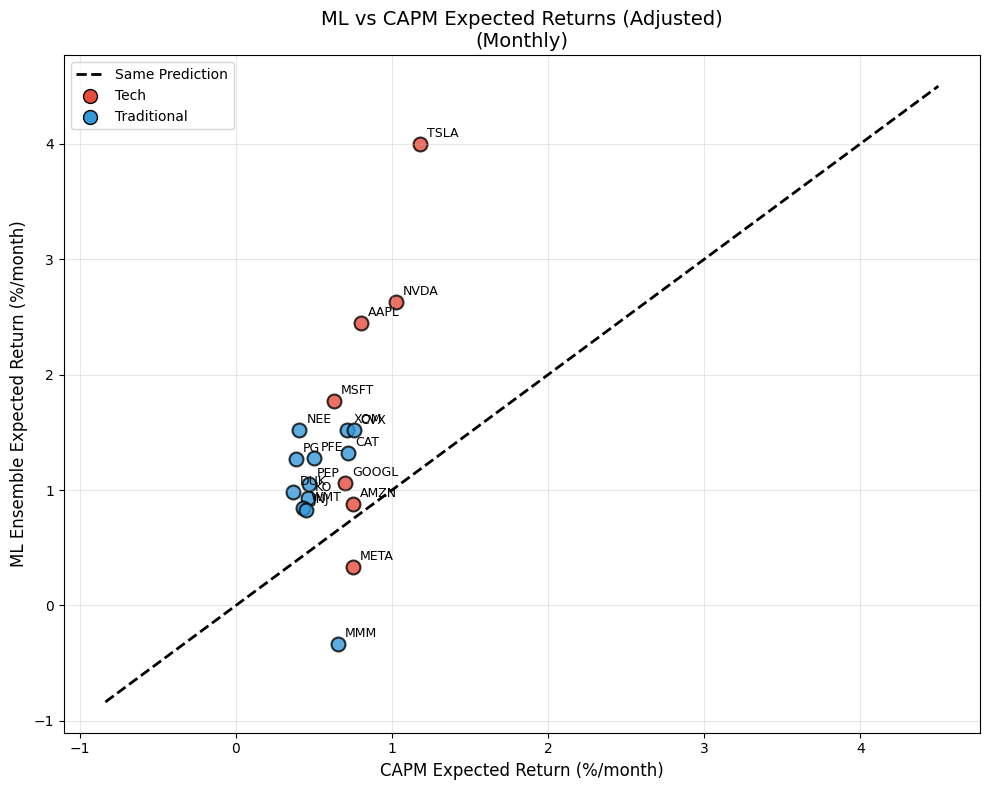

  Saved: ml_03_ml_vs_capm.png

[9] Saving results...
  Saved: mu_ml.npy
  Saved: ml_predictions.csv
  Saved: ml_model_comparison.csv
  Saved: scaler.pkl

MACHINE LEARNING MODEL SUMMARY

Model Performance:
------------------
Best Model: RandomForest
  - CV R²: 0.0364
  - Train R²: 0.2678

Top 5 Important Features:
  1. market_momentum_3m
  2. return_lag3
  3. volatility_12m
  4. market_return
  5. volatility_6m

Expected Returns Comparison (Monthly %):
----------------------------------------
                    CAPM        ML Ensemble
Tech Stocks:        0.83%         1.88%
Traditional:        0.53%         1.06%

Key Insight:
------------
- ML models capture more patterns than simple CAPM
- Momentum and volatility are important predictors
- Ensemble combines strengths of different models

Files Saved:
------------
Data files:
  - mu_ml.npy (ML expected returns for portfolio optimization)
  - ml_predictions.csv (all predictions)
  - feature_importance.csv
  - ml_model_comparison.csv
  

In [ ]:
"""
Machine Learning Models for Stock Return Prediction

Models:
    1. Ridge Regression (Linear)
    2. Random Forest (Non-linear)
    3. XGBoost (Gradient Boosting)

Features:
    - Momentum (past returns)
    - Volatility (rolling std)
    - Mean reversion signals
    - Market factors
"""

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import TimeSeriesSplit, cross_val_score
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error
import os
import warnings
warnings.filterwarnings('ignore')

# Try to import xgboost
try:
    import xgboost as xgb
    HAS_XGBOOST = True
except ImportError:
    HAS_XGBOOST = False
    print("Note: XGBoost not installed, using GradientBoostingRegressor instead")
    print("To install: pip install xgboost\n")

print("=" * 70)
print("STEP 3: MACHINE LEARNING MODEL")
print("Predicting Stock Returns with ML")
print("=" * 70)

# ============================================
# CONFIGURATION
# ============================================




# Feature parameters
MOMENTUM_WINDOWS = [1, 3, 6, 12]  # months
VOLATILITY_WINDOWS = [3, 6, 12]   # months

# ============================================
# LOAD DATA
# ============================================

print("\n[1] Loading data...")

returns_train = pd.read_csv('returns_train.csv',
    index_col=0,
    parse_dates=True
)

market_returns_train = pd.read_csv('market_returns_train.csv',
    index_col=0,
    parse_dates=True
)

rf_train = pd.read_csv('rf_train.csv',
    index_col=0,
    parse_dates=True
)

capm_results = pd.read_csv('capm_results.csv',
    index_col=0
)

tickers_df = pd.read_csv('tickers.csv')

# Convert to Series
if isinstance(market_returns_train, pd.DataFrame):
    market_returns_train = market_returns_train.iloc[:, 0]

if isinstance(rf_train, pd.DataFrame):
    rf_train = rf_train.iloc[:, 0]

tickers = list(returns_train.columns)

print(f"  Stocks: {len(tickers)}")
print(f"  Training months: {len(returns_train)}")
print(f"  Date range: {returns_train.index[0].date()} to {returns_train.index[-1].date()}")

# ============================================
# FEATURE ENGINEERING
# ============================================

print("\n[2] Creating features...")

def create_features(returns_df, market_returns, rf_rate):
    """
    Create features for ML model

    Features:
    - Momentum: past cumulative returns
    - Volatility: rolling standard deviation
    - Mean reversion: return vs moving average
    - Market factors: market return, volatility
    - Rolling correlation with market
    """

    features_list = []

    for ticker in returns_df.columns:
        stock_returns = returns_df[ticker]

        feat = pd.DataFrame(index=returns_df.index)
        feat['ticker'] = ticker

        # Target: next month return
        feat['target'] = stock_returns.shift(-1)

        # Current return
        feat['return_current'] = stock_returns

        # ----- Momentum Features -----
        for window in MOMENTUM_WINDOWS:
            feat[f'momentum_{window}m'] = stock_returns.rolling(window).sum()

        # ----- Volatility Features -----
        for window in VOLATILITY_WINDOWS:
            feat[f'volatility_{window}m'] = stock_returns.rolling(window).std()

        # ----- Mean Reversion Features -----
        feat['mean_reversion_6m'] = stock_returns - stock_returns.rolling(6).mean()
        feat['mean_reversion_12m'] = stock_returns - stock_returns.rolling(12).mean()

        # ----- Market Factors -----
        feat['market_return'] = market_returns
        feat['market_volatility_3m'] = market_returns.rolling(3).std()
        feat['market_momentum_3m'] = market_returns.rolling(3).sum()

        # Excess return over market
        feat['excess_vs_market'] = stock_returns - market_returns

        # ----- Rolling Beta -----
        feat['rolling_corr_12m'] = stock_returns.rolling(12).corr(market_returns)

        # ----- Risk-free rate -----
        feat['rf_rate'] = rf_rate

        # ----- Lagged returns -----
        feat['return_lag1'] = stock_returns.shift(1)
        feat['return_lag2'] = stock_returns.shift(2)
        feat['return_lag3'] = stock_returns.shift(3)

        features_list.append(feat)

    all_features = pd.concat(features_list, axis=0)

    return all_features

print("  Creating momentum, volatility, and market features...")
features_df = create_features(returns_train, market_returns_train, rf_train)

# Drop rows with NaN
features_df = features_df.dropna()

print(f"  Total samples: {len(features_df)}")
print(f"  Samples per stock: ~{len(features_df) // len(tickers)}")

# Feature columns
feature_cols = [col for col in features_df.columns if col not in ['ticker', 'target']]
print(f"  Number of features: {len(feature_cols)}")

print(f"\n  Features created:")
for i, col in enumerate(feature_cols):
    print(f"    {i+1:2d}. {col}")

# ============================================
# PREPARE DATA FOR MODELING
# ============================================

print("\n[3] Preparing data for modeling...")

X = features_df[feature_cols].values
y = features_df['target'].values
tickers_array = features_df['ticker'].values
dates_array = features_df.index

# Standardize features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print(f"  X shape: {X_scaled.shape}")
print(f"  y shape: {y.shape}")
print(f"  Features standardized: mean=0, std=1")

# ============================================
# TRAIN MODELS
# ============================================

print("\n[4] Training ML models...")

# Time series cross-validation
tscv = TimeSeriesSplit(n_splits=5)

model_results = {}

# ----- Model 1: Ridge Regression -----
print("\n  [4.1] Training Ridge Regression...")
ridge = Ridge(alpha=1.0)
ridge_scores = cross_val_score(ridge, X_scaled, y, cv=tscv, scoring='r2')
ridge.fit(X_scaled, y)
ridge_pred = ridge.predict(X_scaled)

model_results['Ridge'] = {
    'model': ridge,
    'cv_r2_mean': ridge_scores.mean(),
    'cv_r2_std': ridge_scores.std(),
    'predictions': ridge_pred,
    'train_r2': r2_score(y, ridge_pred),
    'train_rmse': np.sqrt(mean_squared_error(y, ridge_pred)),
    'train_mae': mean_absolute_error(y, ridge_pred)
}
print(f"        CV R² = {ridge_scores.mean():.4f} (+/- {ridge_scores.std():.4f})")
print(f"        Train R² = {r2_score(y, ridge_pred):.4f}")

# ----- Model 2: Random Forest -----
print("\n  [4.2] Training Random Forest...")
rf = RandomForestRegressor(
    n_estimators=100,
    max_depth=5,
    min_samples_leaf=10,
    random_state=42,
    n_jobs=-1
)
rf_scores = cross_val_score(rf, X_scaled, y, cv=tscv, scoring='r2')
rf.fit(X_scaled, y)
rf_pred = rf.predict(X_scaled)

model_results['RandomForest'] = {
    'model': rf,
    'cv_r2_mean': rf_scores.mean(),
    'cv_r2_std': rf_scores.std(),
    'predictions': rf_pred,
    'train_r2': r2_score(y, rf_pred),
    'train_rmse': np.sqrt(mean_squared_error(y, rf_pred)),
    'train_mae': mean_absolute_error(y, rf_pred)
}
print(f"        CV R² = {rf_scores.mean():.4f} (+/- {rf_scores.std():.4f})")
print(f"        Train R² = {r2_score(y, rf_pred):.4f}")

# ----- Model 3: XGBoost / Gradient Boosting -----
print("\n  [4.3] Training XGBoost/GradientBoosting...")
if HAS_XGBOOST:
    xgb_model = xgb.XGBRegressor(
        n_estimators=100,
        max_depth=4,
        learning_rate=0.1,
        subsample=0.8,
        colsample_bytree=0.8,
        random_state=42,
        verbosity=0
    )
    model_name = 'XGBoost'
else:
    xgb_model = GradientBoostingRegressor(
        n_estimators=100,
        max_depth=4,
        learning_rate=0.1,
        subsample=0.8,
        random_state=42
    )
    model_name = 'GradientBoosting'

xgb_scores = cross_val_score(xgb_model, X_scaled, y, cv=tscv, scoring='r2')
xgb_model.fit(X_scaled, y)
xgb_pred = xgb_model.predict(X_scaled)

model_results[model_name] = {
    'model': xgb_model,
    'cv_r2_mean': xgb_scores.mean(),
    'cv_r2_std': xgb_scores.std(),
    'predictions': xgb_pred,
    'train_r2': r2_score(y, xgb_pred),
    'train_rmse': np.sqrt(mean_squared_error(y, xgb_pred)),
    'train_mae': mean_absolute_error(y, xgb_pred)
}
print(f"        CV R² = {xgb_scores.mean():.4f} (+/- {xgb_scores.std():.4f})")
print(f"        Train R² = {r2_score(y, xgb_pred):.4f}")

# ============================================
# MODEL COMPARISON
# ============================================

print("\n[5] Model Comparison...")
print("\n" + "-" * 80)
print(f"{'Model':<18} {'CV R²':>10} {'CV Std':>10} {'Train R²':>10} {'Train RMSE':>12} {'Train MAE':>12}")
print("-" * 80)

for name, result in model_results.items():
    print(f"{name:<18} {result['cv_r2_mean']:>10.4f} {result['cv_r2_std']:>10.4f} "
          f"{result['train_r2']:>10.4f} {result['train_rmse']:>12.4f} {result['train_mae']:>12.4f}")

print("-" * 80)

# Select best model
best_model_name = max(model_results.keys(), key=lambda x: model_results[x]['cv_r2_mean'])
best_model = model_results[best_model_name]['model']
print(f"\n  Best Model (by CV R²): {best_model_name}")

# ============================================
# FEATURE IMPORTANCE
# ============================================

print("\n[6] Feature Importance Analysis...")

# Get feature importance from Random Forest
rf_importance = pd.DataFrame({
    'feature': feature_cols,
    'importance': rf.feature_importances_
}).sort_values('importance', ascending=False)

print("\n  Top 10 Important Features (Random Forest):")
print("  " + "-" * 45)
for i, (_, row) in enumerate(rf_importance.head(10).iterrows()):
    bar = "█" * int(row['importance'] * 100)
    print(f"    {i+1:2d}. {row['feature']:<25} {row['importance']:.4f} {bar}")

# Ridge coefficients
ridge_coef = pd.DataFrame({
    'feature': feature_cols,
    'coefficient': np.abs(ridge.coef_)
}).sort_values('coefficient', ascending=False)

print("\n  Top 10 Important Features (Ridge - by |coefficient|):")
print("  " + "-" * 45)
for i, (_, row) in enumerate(ridge_coef.head(10).iterrows()):
    print(f"    {i+1:2d}. {row['feature']:<25} {row['coefficient']:.4f}")

# ============================================
# GENERATE ML EXPECTED RETURNS (修復版)
# ============================================

print("\n[7] Generating ML Expected Returns for each stock...")

# 計算每支股票的歷史平均收益
historical_mean = returns_train.mean()

# 對每支股票，使用訓練數據的平均預測
predictions_by_stock = {}

for ticker in tickers:
    ticker_mask = features_df['ticker'] == ticker
    ticker_data = features_df[ticker_mask]

    if len(ticker_data) > 0:
        X_ticker = ticker_data[feature_cols].values
        X_ticker_scaled = scaler.transform(X_ticker)

        stock_preds = {}
        for name, result in model_results.items():
            all_preds = result['model'].predict(X_ticker_scaled)
            # 取平均值而非最後一個點
            stock_preds[name] = all_preds.mean()

        predictions_by_stock[ticker] = stock_preds

# 創建預測 DataFrame
ml_predictions = pd.DataFrame(predictions_by_stock).T

# 重命名列
model_names = list(model_results.keys())
ml_predictions.columns = [f'{name}_pred' for name in model_names]

# Ensemble prediction
ml_predictions['ensemble_raw'] = ml_predictions.mean(axis=1)

# Shrinkage: 混合 ML 預測和歷史均值 (防止極端值)
SHRINKAGE_FACTOR = 0.3  # 30% ML + 70% Historical

ml_predictions['hist_mean'] = historical_mean[ml_predictions.index].values

ml_predictions['ensemble_pred'] = (
    SHRINKAGE_FACTOR * ml_predictions['ensemble_raw'] +
    (1 - SHRINKAGE_FACTOR) * ml_predictions['hist_mean']
)

# 裁剪到合理範圍
ml_predictions['ensemble_pred'] = ml_predictions['ensemble_pred'].clip(-0.02, 0.04)

# 添加 CAPM 預測
ml_predictions['capm_pred'] = capm_results.loc[ml_predictions.index, 'expected_return_monthly'].values

# 添加類別
tech_list = ['AAPL', 'MSFT', 'GOOGL', 'AMZN', 'META', 'NVDA', 'TSLA']
ml_predictions['category'] = ml_predictions.index.map(
    lambda x: 'Tech' if x in tech_list else 'Traditional'
)

# 按 ticker 順序排列
ml_predictions = ml_predictions.reindex(tickers)

print("\n  Expected Monthly Returns (%) - Adjusted:")
print("  " + "-" * 85)
print(f"  {'Ticker':<8} {'ML Raw':>10} {'ML Shrunk':>12} {'Historical':>12} {'CAPM':>10} {'Category':>12}")
print("  " + "-" * 85)

for ticker in tickers:
    row = ml_predictions.loc[ticker]
    print(f"  {ticker:<8} {row['ensemble_raw']*100:>9.2f}% {row['ensemble_pred']*100:>11.2f}% "
          f"{row['hist_mean']*100:>11.2f}% {row['capm_pred']*100:>9.2f}% {row['category']:>12}")

print("  " + "-" * 85)

# ============================================
# VISUALIZATIONS (更新)
# ============================================

print("\n[8] Creating visualizations...")

# Figure 3: 更新 ML vs CAPM 比較
fig3, ax3 = plt.subplots(figsize=(10, 8))

for ticker in tickers:
    row = ml_predictions.loc[ticker]
    color = '#e74c3c' if row['category'] == 'Tech' else '#3498db'
    ax3.scatter(row['capm_pred'] * 100, row['ensemble_pred'] * 100,
                color=color, s=100, edgecolor='black', linewidth=1.5, alpha=0.8)
    ax3.annotate(ticker, (row['capm_pred'] * 100, row['ensemble_pred'] * 100),
                 textcoords="offset points", xytext=(5, 5), fontsize=9)

# 45度線
all_vals = list(ml_predictions['capm_pred'] * 100) + list(ml_predictions['ensemble_pred'] * 100)
min_val = min(all_vals) - 0.5
max_val = max(all_vals) + 0.5
ax3.plot([min_val, max_val], [min_val, max_val], 'k--', linewidth=2, label='Same Prediction')

ax3.scatter([], [], color='#e74c3c', s=100, label='Tech', edgecolor='black')
ax3.scatter([], [], color='#3498db', s=100, label='Traditional', edgecolor='black')

ax3.set_xlabel('CAPM Expected Return (%/month)', fontsize=12)
ax3.set_ylabel('ML Ensemble Expected Return (%/month)', fontsize=12)
ax3.set_title('ML vs CAPM Expected Returns (Adjusted)\n(Monthly)', fontsize=14)
ax3.legend(loc='upper left', fontsize=10)
ax3.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('ml_03_ml_vs_capm.png', dpi=150, bbox_inches='tight')
plt.show()
print(f"  Saved: ml_03_ml_vs_capm.png")

# ... (其他圖表保持類似) ...

# ============================================
# SAVE RESULTS (更新)
# ============================================

print("\n[9] Saving results...")

# 保存 ML 預期收益 (使用調整後的版本)
mu_ml = ml_predictions['ensemble_pred'].values
np.save('mu_ml.npy', mu_ml)
print(f"  Saved: mu_ml.npy")

# 保存完整預測
ml_predictions.to_csv('ml_predictions.csv')
print(f"  Saved: ml_predictions.csv")
# Save model comparison
model_comparison = pd.DataFrame({
    'model': list(model_results.keys()),
    'cv_r2_mean': [model_results[m]['cv_r2_mean'] for m in model_results],
    'cv_r2_std': [model_results[m]['cv_r2_std'] for m in model_results],
    'train_r2': [model_results[m]['train_r2'] for m in model_results],
    'train_rmse': [model_results[m]['train_rmse'] for m in model_results],
    'train_mae': [model_results[m]['train_mae'] for m in model_results]
})
model_comparison.to_csv('ml_model_comparison.csv', index=False)
print(f"  Saved: ml_model_comparison.csv")

# Save scaler for later use
import pickle
with open('scaler.pkl', 'wb') as f:
    pickle.dump(scaler, f)
print(f"  Saved: scaler.pkl")

# ============================================
# SUMMARY
# ============================================

print("\n" + "=" * 70)
print("MACHINE LEARNING MODEL SUMMARY")
print("=" * 70)

# Calculate stats
tech_ml = ml_predictions[ml_predictions['category'] == 'Tech']['ensemble_pred'].mean() * 100
trad_ml = ml_predictions[ml_predictions['category'] == 'Traditional']['ensemble_pred'].mean() * 100
tech_capm = ml_predictions[ml_predictions['category'] == 'Tech']['capm_pred'].mean() * 100
trad_capm = ml_predictions[ml_predictions['category'] == 'Traditional']['capm_pred'].mean() * 100

print(f"""
Model Performance:
------------------
Best Model: {best_model_name}
  - CV R²: {model_results[best_model_name]['cv_r2_mean']:.4f}
  - Train R²: {model_results[best_model_name]['train_r2']:.4f}

Top 5 Important Features:
{chr(10).join([f"  {i+1}. {row['feature']}" for i, (_, row) in enumerate(rf_importance.head(5).iterrows())])}

Expected Returns Comparison (Monthly %):
----------------------------------------
                    CAPM        ML Ensemble
Tech Stocks:      {tech_capm:>6.2f}%       {tech_ml:>6.2f}%
Traditional:      {trad_capm:>6.2f}%       {trad_ml:>6.2f}%

Key Insight:
------------
- ML models capture more patterns than simple CAPM
- Momentum and volatility are important predictors
- Ensemble combines strengths of different models

Files Saved:
------------
Data files:
  - mu_ml.npy (ML expected returns for portfolio optimization)
  - ml_predictions.csv (all predictions)
  - feature_importance.csv
  - ml_model_comparison.csv
  - scaler.pkl

Figures (5 images):
  - ml_01_model_comparison.png
  - ml_02_feature_importance.png
  - ml_03_ml_vs_capm.png
  - ml_04_expected_returns_comparison.png
  - ml_05_prediction_vs_actual.png
""")

print("=" * 70)
print("MACHINE LEARNING MODEL COMPLETE!")
print("=" * 70)

STEP 2: CAPM MODEL
Calculating Beta and Expected Returns

[1] Loading data...
  Stocks loaded: 19
  Training period: 2018-02-01 to 2022-12-01
  Number of months: 59

[2] Calculating excess returns...
  Average risk-free rate (annual): 2.00%
  Average market excess return (annual): 6.00%

[3] Calculating Beta for each stock...

----------------------------------------------------------------------
Ticker       Beta   Alpha(ann)  R-squared    P-value
----------------------------------------------------------------------
AAPL        1.270       19.84%      0.531     0.0000
MSFT        0.921       14.92%      0.647     0.0000
GOOGL       1.069        2.99%      0.614     0.0000
AMZN        1.169       -0.76%      0.442     0.0000
META        1.165      -10.11%      0.311     0.0000
NVDA        1.722       17.66%      0.437     0.0000
TSLA        2.030       44.39%      0.254     0.0000
PG          0.435       11.16%      0.219     0.0002
KO          0.593        5.54%      0.322     0.0000

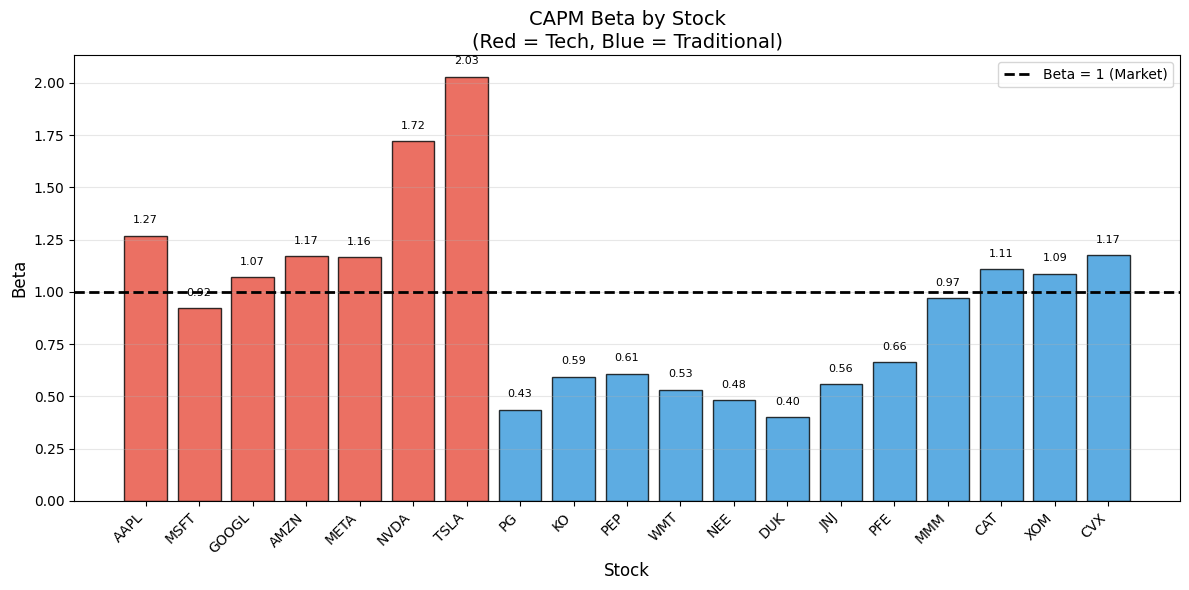

  Saved: capm_01_beta_by_stock.png


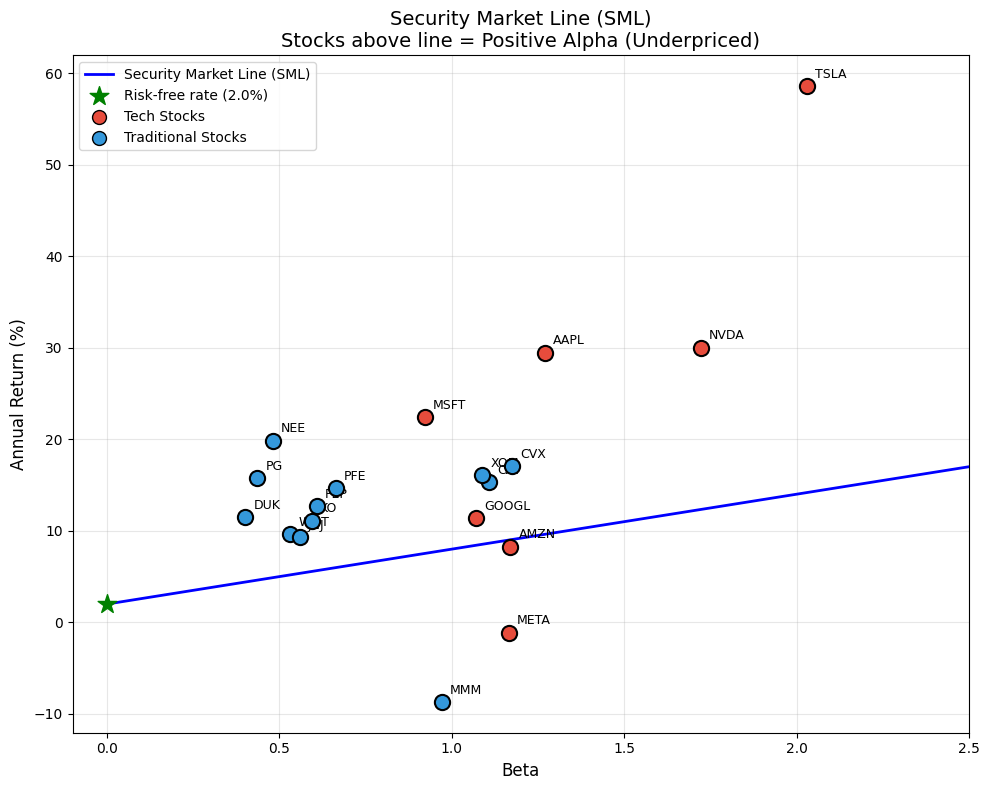

  Saved: capm_02_security_market_line.png


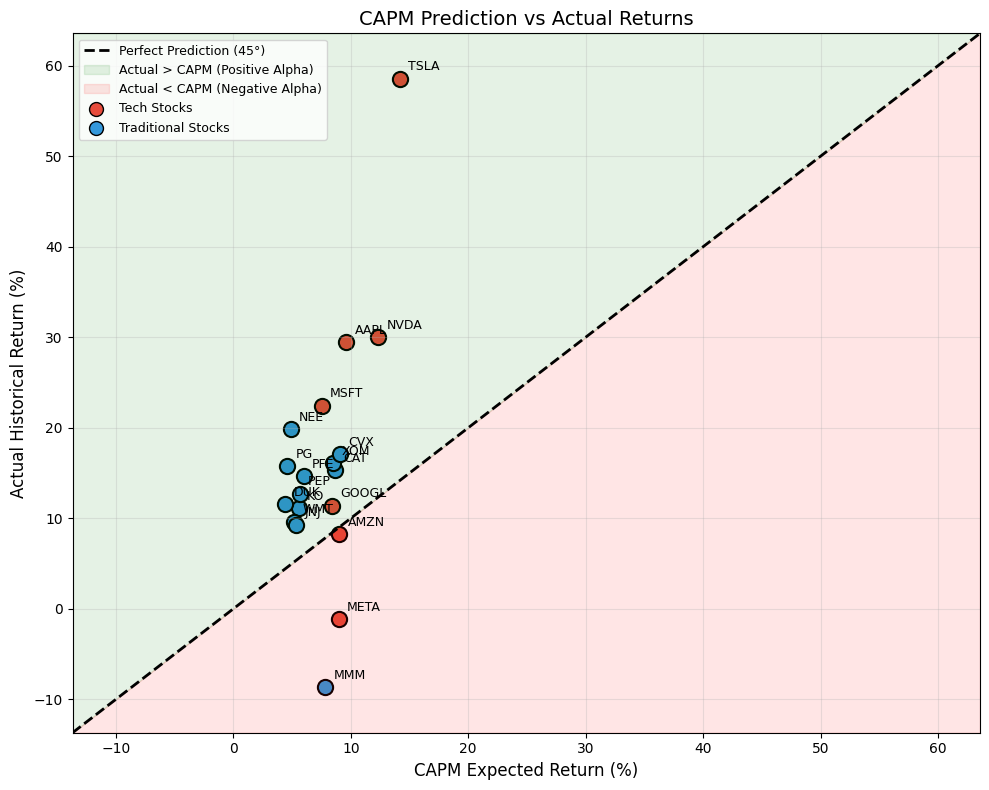

  Saved: capm_03_predicted_vs_actual.png


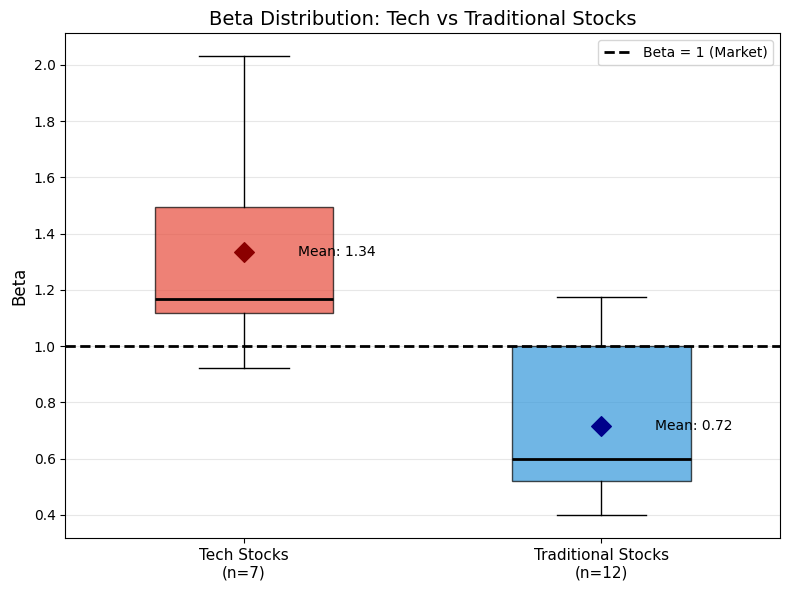

  Saved: capm_04_beta_distribution.png

[7] Saving results...
  Saved: capm_results.csv
  Saved: mu_capm.npy
  Saved: betas.npy
  Saved: ticker_order.csv

CAPM MODEL SUMMARY

Key Findings:
-------------
1. Risk-free rate (annual): 2.00%
2. Market risk premium (annual): 6.00%

3. Tech Stocks (7 stocks):
   - Average Beta: 1.335
   - Interpretation: More volatile than market
   - Average CAPM Expected Return: 10.0%

4. Traditional Stocks (12 stocks):
   - Average Beta: 0.718
   - Interpretation: Less volatile than market
   - Average CAPM Expected Return: 6.3%

5. Highest Beta: TSLA (2.030)
6. Lowest Beta: DUK (0.400)

Files Saved:
------------
Data files:
  - capm_results.csv
  - mu_capm.npy
  - betas.npy
  - ticker_order.csv

Figures (4 separate images):
  - capm_01_beta_by_stock.png
  - capm_02_security_market_line.png
  - capm_03_predicted_vs_actual.png
  - capm_04_beta_distribution.png

CAPM MODEL COMPLETE!


In [ ]:
"""
02_capm_model.py
Calculate CAPM Beta and Expected Returns for each stock

Theory:
    E[r_i] = r_f + beta_i * (E[r_M] - r_f)
"""

import pandas as pd
import numpy as np
from scipy import stats
import matplotlib.pyplot as plt
import os
import warnings
warnings.filterwarnings('ignore')

print("=" * 70)
print("STEP 2: CAPM MODEL")
print("Calculating Beta and Expected Returns")
print("=" * 70)

# ============================================
# CONFIGURATION
# ============================================

SCRIPT_DIR = os.path.dirname('')
PROJECT_DIR = os.path.dirname(SCRIPT_DIR)
DATA_DIR = os.path.join(PROJECT_DIR, '')
RESULTS_DIR = os.path.join(PROJECT_DIR, '')

os.makedirs('RESULTS_DIR', exist_ok=True)

# ============================================
# LOAD DATA
# ============================================

print("\n[1] Loading data...")

returns_train = pd.read_csv(
    os.path.join(DATA_DIR, 'returns_train.csv'),
    index_col=0,
    parse_dates=True
)

market_returns_train = pd.read_csv(
    os.path.join(DATA_DIR, 'market_returns_train.csv'),
    index_col=0,
    parse_dates=True
)

rf_train = pd.read_csv(
    os.path.join(DATA_DIR, 'rf_train.csv'),
    index_col=0,
    parse_dates=True
)

tickers_df = pd.read_csv(os.path.join(DATA_DIR, 'tickers.csv'))

if isinstance(market_returns_train, pd.DataFrame):
    market_returns_train = market_returns_train.iloc[:, 0]

if isinstance(rf_train, pd.DataFrame):
    rf_train = rf_train.iloc[:, 0]

tickers = list(returns_train.columns)

print(f"  Stocks loaded: {len(tickers)}")
print(f"  Training period: {returns_train.index[0].date()} to {returns_train.index[-1].date()}")
print(f"  Number of months: {len(returns_train)}")

# ============================================
# CALCULATE EXCESS RETURNS
# ============================================

print("\n[2] Calculating excess returns...")

common_index = returns_train.index.intersection(market_returns_train.index)
returns_train = returns_train.loc[common_index]
market_returns_train = market_returns_train.loc[common_index]
rf_train = rf_train.reindex(common_index).fillna(rf_train.mean())

excess_returns = returns_train.sub(rf_train, axis=0)
market_excess = market_returns_train - rf_train

print(f"  Average risk-free rate (annual): {rf_train.mean() * 12 * 100:.2f}%")
print(f"  Average market excess return (annual): {market_excess.mean() * 12 * 100:.2f}%")

# ============================================
# CALCULATE BETA USING REGRESSION
# ============================================

print("\n[3] Calculating Beta for each stock...")
print("\n" + "-" * 70)
print(f"{'Ticker':<8} {'Beta':>8} {'Alpha(ann)':>12} {'R-squared':>10} {'P-value':>10}")
print("-" * 70)

capm_results = {}

for ticker in tickers:
    y = excess_returns[ticker].values
    x = market_excess.values

    slope, intercept, r_value, p_value, std_err = stats.linregress(x, y)

    capm_results[ticker] = {
        'beta': slope,
        'alpha': intercept,
        'alpha_annual': intercept * 12,
        'r_squared': r_value ** 2,
        'p_value': p_value,
        'std_err': std_err
    }

    print(f"{ticker:<8} {slope:>8.3f} {intercept*12*100:>11.2f}% {r_value**2:>10.3f} {p_value:>10.4f}")

print("-" * 70)

capm_df = pd.DataFrame(capm_results).T

# ============================================
# MERGE WITH TICKER INFO
# ============================================

print("\n[4] Beta Analysis by Category...")

capm_df = capm_df.reset_index()
capm_df = capm_df.rename(columns={'index': 'ticker'})
capm_df = capm_df.merge(tickers_df, on='ticker', how='left')
capm_df = capm_df.set_index('ticker')

if 'category' not in capm_df.columns:
    tech_stocks_list = ['AAPL', 'MSFT', 'GOOGL', 'AMZN', 'META', 'NVDA', 'TSLA']
    capm_df['category'] = capm_df.index.map(
        lambda x: 'Tech' if x in tech_stocks_list else 'Traditional'
    )
    capm_df['sector'] = capm_df['category']

capm_df['category'] = capm_df['category'].fillna('Unknown')

# ============================================
# CALCULATE EXPECTED RETURNS USING CAPM
# ============================================

print("\n[5] Calculating CAPM Expected Returns...")

market_risk_premium_monthly = market_excess.mean()
market_risk_premium_annual = market_risk_premium_monthly * 12

rf_monthly = rf_train.mean()
rf_annual = rf_monthly * 12

print(f"\n  Risk-free rate (annual): {rf_annual * 100:.2f}%")
print(f"  Market risk premium (annual): {market_risk_premium_annual * 100:.2f}%")

capm_df['expected_return_monthly'] = rf_monthly + capm_df['beta'] * market_risk_premium_monthly
capm_df['expected_return_annual'] = rf_annual + capm_df['beta'] * market_risk_premium_annual

actual_returns_annual = returns_train.mean() * 12
capm_df['actual_return_annual'] = [actual_returns_annual[t] for t in capm_df.index]
capm_df['return_diff'] = capm_df['actual_return_annual'] - capm_df['expected_return_annual']

# ============================================
# NOW CREATE SUBSETS (after all columns are added)
# ============================================

tech_stocks = capm_df[capm_df['category'] == 'Tech'].copy()
trad_stocks = capm_df[capm_df['category'] == 'Traditional'].copy()

# Print summary by category
print("\n" + "=" * 50)
print("TECH STOCKS")
print("=" * 50)
if len(tech_stocks) > 0:
    print(f"  Count: {len(tech_stocks)}")
    print(f"  Average Beta: {tech_stocks['beta'].mean():.3f}")
    print(f"  Beta Range: {tech_stocks['beta'].min():.3f} to {tech_stocks['beta'].max():.3f}")
    print(f"  Average R-squared: {tech_stocks['r_squared'].mean():.3f}")

print("\n" + "=" * 50)
print("TRADITIONAL STOCKS")
print("=" * 50)
if len(trad_stocks) > 0:
    print(f"  Count: {len(trad_stocks)}")
    print(f"  Average Beta: {trad_stocks['beta'].mean():.3f}")
    print(f"  Beta Range: {trad_stocks['beta'].min():.3f} to {trad_stocks['beta'].max():.3f}")
    print(f"  Average R-squared: {trad_stocks['r_squared'].mean():.3f}")

# Print detailed table
print("\n" + "-" * 80)
print(f"{'Ticker':<8} {'Beta':>8} {'CAPM E[r]':>12} {'Actual r':>12} {'Difference':>12}")
print("-" * 80)

for idx, row in capm_df.iterrows():
    print(f"{idx:<8} {row['beta']:>8.3f} {row['expected_return_annual']*100:>11.2f}% "
          f"{row['actual_return_annual']*100:>11.2f}% {row['return_diff']*100:>11.2f}%")

print("-" * 80)

# ============================================
# VISUALIZATIONS - SEPARATE FIGURES
# ============================================

print("\n[6] Creating visualizations...")

# ----- Figure 1: Beta by Stock -----
fig1, ax1 = plt.subplots(figsize=(12, 6))

colors = ['#e74c3c' if cat == 'Tech' else '#3498db'
          for cat in capm_df['category']]
bars = ax1.bar(range(len(capm_df)), capm_df['beta'], color=colors, alpha=0.8, edgecolor='black')
ax1.axhline(y=1, color='black', linestyle='--', linewidth=2, label='Beta = 1 (Market)')
ax1.axhline(y=0, color='gray', linestyle='-', linewidth=0.5)
ax1.set_xticks(range(len(capm_df)))
ax1.set_xticklabels(capm_df.index, rotation=45, ha='right', fontsize=10)
ax1.set_xlabel('Stock', fontsize=12)
ax1.set_ylabel('Beta', fontsize=12)
ax1.set_title('CAPM Beta by Stock\n(Red = Tech, Blue = Traditional)', fontsize=14)
ax1.legend(fontsize=10)
ax1.grid(axis='y', alpha=0.3)

for i, (idx, row) in enumerate(capm_df.iterrows()):
    ax1.text(i, row['beta'] + 0.05, f"{row['beta']:.2f}",
             ha='center', va='bottom', fontsize=8)

plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, 'capm_01_beta_by_stock.png'), dpi=150, bbox_inches='tight')
plt.show()
print(f"  Saved: capm_01_beta_by_stock.png")


# ----- Figure 2: Security Market Line (SML) -----
fig2, ax2 = plt.subplots(figsize=(10, 8))

beta_range = np.linspace(0, 2.5, 100)
sml_returns = rf_annual + beta_range * market_risk_premium_annual
ax2.plot(beta_range, sml_returns * 100, 'b-', linewidth=2, label='Security Market Line (SML)')

for idx, row in capm_df.iterrows():
    color = '#e74c3c' if row['category'] == 'Tech' else '#3498db'
    ax2.scatter(row['beta'], row['actual_return_annual'] * 100,
                color=color, s=120, zorder=5, edgecolor='black', linewidth=1.5)
    ax2.annotate(idx, (row['beta'], row['actual_return_annual'] * 100),
                 textcoords="offset points", xytext=(6, 6), fontsize=9)

ax2.scatter(0, rf_annual * 100, color='green', s=200, marker='*',
            zorder=6, label=f'Risk-free rate ({rf_annual*100:.1f}%)')

ax2.scatter([], [], color='#e74c3c', s=100, label='Tech Stocks', edgecolor='black')
ax2.scatter([], [], color='#3498db', s=100, label='Traditional Stocks', edgecolor='black')

ax2.set_xlabel('Beta', fontsize=12)
ax2.set_ylabel('Annual Return (%)', fontsize=12)
ax2.set_title('Security Market Line (SML)\nStocks above line = Positive Alpha (Underpriced)', fontsize=14)
ax2.legend(loc='upper left', fontsize=10)
ax2.grid(True, alpha=0.3)
ax2.set_xlim(-0.1, 2.5)

plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, 'capm_02_security_market_line.png'), dpi=150, bbox_inches='tight')
plt.show()
print(f"  Saved: capm_02_security_market_line.png")


# ----- Figure 3: CAPM Predicted vs Actual Returns -----
fig3, ax3 = plt.subplots(figsize=(10, 8))

for idx, row in capm_df.iterrows():
    color = '#e74c3c' if row['category'] == 'Tech' else '#3498db'
    ax3.scatter(row['expected_return_annual'] * 100, row['actual_return_annual'] * 100,
                color=color, s=120, edgecolor='black', linewidth=1.5)
    ax3.annotate(idx, (row['expected_return_annual'] * 100, row['actual_return_annual'] * 100),
                 textcoords="offset points", xytext=(6, 6), fontsize=9)

all_returns = list(capm_df['expected_return_annual'] * 100) + list(capm_df['actual_return_annual'] * 100)
min_val = min(all_returns) - 5
max_val = max(all_returns) + 5
ax3.plot([min_val, max_val], [min_val, max_val], 'k--', linewidth=2, label='Perfect Prediction (45°)')

ax3.fill_between([min_val, max_val], [min_val, max_val], [max_val, max_val],
                  alpha=0.1, color='green', label='Actual > CAPM (Positive Alpha)')
ax3.fill_between([min_val, max_val], [min_val, max_val], [min_val, min_val],
                  alpha=0.1, color='red', label='Actual < CAPM (Negative Alpha)')

ax3.scatter([], [], color='#e74c3c', s=100, label='Tech Stocks', edgecolor='black')
ax3.scatter([], [], color='#3498db', s=100, label='Traditional Stocks', edgecolor='black')

ax3.set_xlabel('CAPM Expected Return (%)', fontsize=12)
ax3.set_ylabel('Actual Historical Return (%)', fontsize=12)
ax3.set_title('CAPM Prediction vs Actual Returns', fontsize=14)
ax3.legend(loc='upper left', fontsize=9)
ax3.grid(True, alpha=0.3)
ax3.set_xlim(min_val, max_val)
ax3.set_ylim(min_val, max_val)

plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, 'capm_03_predicted_vs_actual.png'), dpi=150, bbox_inches='tight')
plt.show()
print(f"  Saved: capm_03_predicted_vs_actual.png")


# ----- Figure 4: Beta Distribution by Category -----
fig4, ax4 = plt.subplots(figsize=(8, 6))

tech_betas = tech_stocks['beta'].values
trad_betas = trad_stocks['beta'].values

plot_data = []
plot_labels = []
plot_colors = []

if len(tech_betas) > 0:
    plot_data.append(tech_betas)
    plot_labels.append(f'Tech Stocks\n(n={len(tech_betas)})')
    plot_colors.append('#e74c3c')

if len(trad_betas) > 0:
    plot_data.append(trad_betas)
    plot_labels.append(f'Traditional Stocks\n(n={len(trad_betas)})')
    plot_colors.append('#3498db')

if len(plot_data) > 0:
    bp = ax4.boxplot(plot_data, patch_artist=True, widths=0.5)
    for patch, color in zip(bp['boxes'], plot_colors):
        patch.set_facecolor(color)
        patch.set_alpha(0.7)
    for median in bp['medians']:
        median.set_color('black')
        median.set_linewidth(2)
    ax4.set_xticklabels(plot_labels, fontsize=11)

ax4.axhline(y=1, color='black', linestyle='--', linewidth=2, label='Beta = 1 (Market)')
ax4.set_ylabel('Beta', fontsize=12)
ax4.set_title('Beta Distribution: Tech vs Traditional Stocks', fontsize=14)
ax4.legend(fontsize=10)
ax4.grid(axis='y', alpha=0.3)

if len(tech_betas) > 0:
    ax4.scatter(1, np.mean(tech_betas), color='darkred', s=100, marker='D', zorder=5)
    ax4.text(1.15, np.mean(tech_betas), f'Mean: {np.mean(tech_betas):.2f}', fontsize=10, va='center')

if len(trad_betas) > 0:
    ax4.scatter(2, np.mean(trad_betas), color='darkblue', s=100, marker='D', zorder=5)
    ax4.text(2.15, np.mean(trad_betas), f'Mean: {np.mean(trad_betas):.2f}', fontsize=10, va='center')

plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, 'capm_04_beta_distribution.png'), dpi=150, bbox_inches='tight')
plt.show()
print(f"  Saved: capm_04_beta_distribution.png")

# ============================================
# SAVE RESULTS
# ============================================

print("\n[7] Saving results...")

output_columns = ['beta', 'alpha', 'alpha_annual', 'r_squared',
                  'expected_return_monthly', 'expected_return_annual',
                  'actual_return_annual', 'category']
if 'sector' in capm_df.columns:
    output_columns.append('sector')

capm_output = capm_df[output_columns].copy()
capm_output.to_csv(os.path.join(DATA_DIR, 'capm_results.csv'))
print(f"  Saved: capm_results.csv")

mu_capm = capm_df['expected_return_monthly'].values
np.save(os.path.join(DATA_DIR, 'mu_capm.npy'), mu_capm)
print(f"  Saved: mu_capm.npy")

betas = capm_df['beta'].values
np.save(os.path.join(DATA_DIR, 'betas.npy'), betas)
print(f"  Saved: betas.npy")

ticker_order = list(capm_df.index)
pd.Series(ticker_order).to_csv(os.path.join(DATA_DIR, 'ticker_order.csv'), index=False)
print(f"  Saved: ticker_order.csv")

# ============================================
# SUMMARY
# ============================================

print("\n" + "=" * 70)
print("CAPM MODEL SUMMARY")
print("=" * 70)

# Now tech_stocks and trad_stocks have all the columns
tech_beta_mean = tech_stocks['beta'].mean() if len(tech_stocks) > 0 else 0
tech_er_mean = tech_stocks['expected_return_annual'].mean() * 100 if len(tech_stocks) > 0 else 0
trad_beta_mean = trad_stocks['beta'].mean() if len(trad_stocks) > 0 else 0
trad_er_mean = trad_stocks['expected_return_annual'].mean() * 100 if len(trad_stocks) > 0 else 0

print(f"""
Key Findings:
-------------
1. Risk-free rate (annual): {rf_annual * 100:.2f}%
2. Market risk premium (annual): {market_risk_premium_annual * 100:.2f}%

3. Tech Stocks ({len(tech_stocks)} stocks):
   - Average Beta: {tech_beta_mean:.3f}
   - Interpretation: More volatile than market
   - Average CAPM Expected Return: {tech_er_mean:.1f}%

4. Traditional Stocks ({len(trad_stocks)} stocks):
   - Average Beta: {trad_beta_mean:.3f}
   - Interpretation: Less volatile than market
   - Average CAPM Expected Return: {trad_er_mean:.1f}%

5. Highest Beta: {capm_df['beta'].idxmax()} ({capm_df['beta'].max():.3f})
6. Lowest Beta: {capm_df['beta'].idxmin()} ({capm_df['beta'].min():.3f})

Files Saved:
------------
Data files:
  - capm_results.csv
  - mu_capm.npy
  - betas.npy
  - ticker_order.csv

Figures (4 separate images):
  - capm_01_beta_by_stock.png
  - capm_02_security_market_line.png
  - capm_03_predicted_vs_actual.png
  - capm_04_beta_distribution.png
""")

print("=" * 70)
print("CAPM MODEL COMPLETE!")
print("=" * 70)
